# ECS708 Machine Learning: Fashion-MNIST investigation

**Research question.** What structure exists in Fashion-MNIST, how can different machine-learning models exploit that structure, and what do their successes and failures teach us about the data and its representations?

**How to read this notebook.** Headings and figure captions carry the coursework task IDs (e.g. *addresses 1.4*). Every key result states its **split, metric, configuration and variability**. The notebook is meant to run top to bottom with *Restart and run all* (about 12 to 15 minutes on a 2-core CPU, no GPU). All experiments are logged in `results/experiment_register.csv` (rule R3); the fixed partitions are in `splits/` (rule R1, Part 0).

**Contents so far:** Part 0 (setup), Part 1 (classical classification). Later parts are appended below.

## Part 0: setup, data roles, fixed partitions, computing (addresses 0.1, 0.2)

This notebook is **self-contained**: it does not import any helper module from the repository. Everything that creates or uses the partitions is in the cells below (`scripts/` and `src/` are not needed). It needs the repository folder as working directory and the four Fashion-MNIST `.gz` files in `data/fashion/` (they are downloaded with `torchvision` if missing).

* **Data.** Fashion-MNIST, 28×28 greyscale, 10 classes; 60,000 official train and 10,000 official test images.
* **Partitions (frozen, 0.1).** All use `sklearn.model_selection.train_test_split(stratify=labels, random_state=708)`; labels are used only to stratify. The index arrays are saved to `splits/splits_seed708.npz` the first time; on every later run the notebook **re-creates the indices and asserts they equal the saved ones**, so the partitions cannot drift.
* **Index convention (important).** `train_idx`, `val_idx`, `cluster_train_idx` and `cluster_val_idx` are positions in the **official 60,000-image training array**; `cluster_test_idx` is a position in the **official 10,000-image test array**. `train_subset10k_idx` and `cluster_train_idx` are subsets *of `train_idx`*, and `cluster_val_idx` is a subset *of `val_idx`*: they index the original array, not the 50,000-image partition.
* **Data roles.** *Train* fits parameters. *Validation* chooses hyperparameters (regularisation strength, tree depth, smoothing, decision thresholds). *Test* gives the final estimate only: this notebook reads **only the test labels** (needed to stratify the clustering test subset) until the guarded final cell of Part 1 loads the test images (rules R1, R6, R7). No test image has been inspected.
* **Preprocessing.** Pixels are divided by 255, so features lie in [0, 1]. This fixed transform uses no data statistics, so nothing fitted can leak between partitions (rule R2). No scaler is fitted anywhere in Part 1.
* **Seeds.** Seed 708 for all partitions, the tree's tie-breaking and example sampling; the tree is also refitted with seeds 1 and 2. Logistic regression (L-BFGS from zero initialisation) and naive Bayes are deterministic.
* **CPU option (0.1.4).** The 10,000-image training subset is created and saved but **not used**: the full 50,000 images fit on a CPU in minutes (fit and prediction times are in the table in the Part 1 summary).

In [1]:
import os, platform, time, json, gzip, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_curve, roc_auc_score, log_loss

ROOT = Path.cwd()                                   # run from the repository root
DATA_DIR, SPLITS_DIR = ROOT / "data" / "fashion", ROOT / "splits"
FIG_DIR, RES_DIR = ROOT / "figures", ROOT / "results" / "part1"
for d in (DATA_DIR, SPLITS_DIR, FIG_DIR, RES_DIR): d.mkdir(parents=True, exist_ok=True)
REGISTER_PATH = ROOT / "results" / "experiment_register.csv"

SEED = 708
np.random.seed(SEED)
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
SHORT = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

# ----------------------------------------------------------------- data files
FILES = {"tr_x": "train-images-idx3-ubyte.gz", "tr_y": "train-labels-idx1-ubyte.gz", "te_x": "t10k-images-idx3-ubyte.gz", "te_y": "t10k-labels-idx1-ubyte.gz"}
def ensure_downloaded():
    if all((DATA_DIR / f).exists() for f in FILES.values()): return
    from torchvision.datasets import FashionMNIST            # only used to download the official files
    for train in (True, False): FashionMNIST(ROOT / "data" / "_tv", train=train, download=True)
    for f in FILES.values(): (DATA_DIR / f).write_bytes((ROOT / "data" / "_tv" / "FashionMNIST" / "raw" / f).read_bytes())
def read_images(name):
    with gzip.open(DATA_DIR / name, "rb") as f: return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784)
def read_labels(name):
    with gzip.open(DATA_DIR / name, "rb") as f: return np.frombuffer(f.read(), np.uint8, offset=8).astype(np.int64)
def prep(X): return (X / 255.0).astype(np.float32)           # fixed transform, no fitted statistics (R2)

ensure_downloaded()
X_off, y_off = read_images(FILES["tr_x"]), read_labels(FILES["tr_y"])   # official TRAIN set (60,000)
y_test_labels = read_labels(FILES["te_y"])                               # test LABELS only; test images stay unread (R1, R6, R7)

# ----------------------------------------------------------------- 0.1 fixed stratified partitions
def stratified_pick(indices, labels, n):
    picked, _ = train_test_split(indices, train_size=n, stratify=labels, random_state=SEED)
    return np.sort(picked)
all_idx = np.arange(len(y_off))
train_idx, val_idx = train_test_split(all_idx, test_size=10_000, stratify=y_off, random_state=SEED)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)
IDX = dict(train_idx=train_idx, val_idx=val_idx,
           train_subset10k_idx=stratified_pick(train_idx, y_off[train_idx], 10_000),            # CPU option, unused
           cluster_train_idx=stratified_pick(train_idx, y_off[train_idx], 3_000),               # indexes official TRAIN array
           cluster_val_idx=stratified_pick(val_idx, y_off[val_idx], 1_000),                     # indexes official TRAIN array
           cluster_test_idx=stratified_pick(np.arange(len(y_test_labels)), y_test_labels, 1_000))  # indexes official TEST array
assert len(np.intersect1d(train_idx, val_idx)) == 0 and len(train_idx) + len(val_idx) == 60_000
assert np.isin(IDX["cluster_train_idx"], train_idx).all() and np.isin(IDX["cluster_val_idx"], val_idx).all()
assert np.isin(IDX["train_subset10k_idx"], train_idx).all()

npz = SPLITS_DIR / f"splits_seed{SEED}.npz"
if npz.exists():
    with np.load(npz) as old: assert all(np.array_equal(old[k], v) for k, v in IDX.items()), "saved splits differ: partitions are frozen"
    print("Saved partitions found and reproduced exactly.")
else:
    np.savez_compressed(npz, **IDX); print("Partitions created and saved to", npz.relative_to(ROOT))
y_all = {"train_idx": y_off, "val_idx": y_off, "train_subset10k_idx": y_off, "cluster_train_idx": y_off, "cluster_val_idx": y_off, "cluster_test_idx": y_test_labels}
counts = pd.DataFrame({k: np.bincount(y_all[k][v], minlength=10) for k, v in IDX.items()}, index=CLASS_NAMES)
counts.loc["TOTAL"] = counts.sum()
print("Images per class in every partition (stratified: balanced):"); display(counts)
json.dump({"seed": SEED, "method": "train_test_split(stratify=labels, random_state=seed)", "sizes": {k: int(len(v)) for k, v in IDX.items()},
           "index_convention": "all index the official 60k train array except cluster_test_idx (official 10k test array)"},
          open(SPLITS_DIR / f"splits_seed{SEED}.json", "w"), indent=2)

Xtr, ytr = prep(X_off[train_idx]), y_off[train_idx]
Xva, yva = prep(X_off[val_idx]), y_off[val_idx]
print(f"train {Xtr.shape} | validation {Xva.shape} | test images not loaded")

# ----------------------------------------------------------------- 0.2 computing
def cpu_name():
    try: return next(l.split(":")[1].strip() for l in open("/proc/cpuinfo") if "model name" in l)
    except Exception: return platform.processor() or "unknown"
print("Hardware (0.2):", cpu_name(), "|", os.cpu_count(), "logical CPUs | no GPU used")
print("Python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

# ----------------------------------------------------------------- small helpers (all of them are here, nothing is imported from the repo)
FIG_INDEX, TIMES = [], []
def save_fig(fig, name, tasks, caption):
    path = FIG_DIR / f"{name}.png"; fig.savefig(path, dpi=150, bbox_inches="tight")
    FIG_INDEX.append({"file": f"figures/{path.name}", "tasks": tasks, "produced_by": "ecs708_fashion_mnist.ipynb", "caption": caption})

def timed_fit(model, X, y, label=""):
    """Fit and time; return (model, seconds, warning messages). Warnings are kept so they can be reported, not hidden."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always"); t0 = time.perf_counter(); model.fit(X, y); sec = time.perf_counter() - t0
    TIMES.append({"what": f"fit {label}", "seconds": sec}); return model, sec, sorted({str(w.message).split("\n")[0][:80] for w in caught})

def timed_predict(model, X, label=""):
    t0 = time.perf_counter(); p = model.predict(X); TIMES.append({"what": f"predict {label} ({len(X)} images)", "seconds": time.perf_counter() - t0}); return p

def wilson_interval(k, n, z=1.96):
    """95% Wilson interval for k/n: sampling uncertainty of the evaluation set only."""
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(10), zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=range(10))
    return pd.DataFrame({"class": CLASS_NAMES, "support": s, "correct (TP)": np.diag(cm), "recall": r, "predicted as class": cm.sum(0), "precision": p, "F1": f})

def top_confusions(y_true, y_pred, k=6):
    cm = confusion_matrix(y_true, y_pred, labels=range(10)); off = cm.copy(); np.fill_diagonal(off, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:k], off.shape))[0]
    return pd.DataFrame([{"true": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "count": int(off[i, j]), "share of true class": off[i, j] / cm[i].sum()} for i, j in idx])

# experiment register (rule R3): one row per experiment in results/experiment_register.csv
REGISTER_COLUMNS = ["id", "part_task", "question", "hypothesis", "changed_variable", "fixed_conditions", "split", "seed", "configuration", "metric", "result", "output_path", "notes"]
def reset_register(prefix):
    df = pd.read_csv(REGISTER_PATH, dtype=str).fillna("") if REGISTER_PATH.exists() else pd.DataFrame(columns=REGISTER_COLUMNS)
    df[~df["id"].str.startswith(prefix)].reindex(columns=REGISTER_COLUMNS, fill_value="").to_csv(REGISTER_PATH, index=False)
def log_experiment(**row):
    df = pd.read_csv(REGISTER_PATH, dtype=str).fillna("")
    pd.concat([df, pd.DataFrame([{c: str(row.get(c, "")) for c in REGISTER_COLUMNS}])], ignore_index=True).to_csv(REGISTER_PATH, index=False)

Saved partitions found and reproduced exactly.
Images per class in every partition (stratified: balanced):


,train_idx,val_idx,train_subset10k_idx,cluster_train_idx,cluster_val_idx,cluster_test_idx
T-shirt/top,5000,1000,1000,300,100,100
Trouser,5000,1000,1000,300,100,100
Pullover,5000,1000,1000,300,100,100
Dress,5000,1000,1000,300,100,100
Coat,5000,1000,1000,300,100,100
Sandal,5000,1000,1000,300,100,100
Shirt,5000,1000,1000,300,100,100
Sneaker,5000,1000,1000,300,100,100
Bag,5000,1000,1000,300,100,100
Ankle boot,5000,1000,1000,300,100,100


train (50000, 784) | validation (10000, 784) | test images not loaded
Hardware (0.2): Intel(R) Xeon(R) Processor @ 2.10GHz | 2 logical CPUs | no GPU used
Python 3.13.18 | numpy 2.5.3 | scikit-learn 1.9.1 | pandas 3.0.5


---
# Part 1: Classical classification

*Guiding question: how do different classifiers use the same data, and what can their errors tell us?*

## Design of the experiments (rules R1, R3, R4)

| Item | Choice |
|---|---|
| Data | Same 50,000 training images and same 10,000 validation images for every model (R4). Test sealed. |
| Models | Multinomial logistic regression (L2), decision tree (entropy), Gaussian naive Bayes (see 1.1). |
| Complexity knob (1.4) | LR: inverse regularisation strength `C`. Tree: `max_depth`. NB: `var_smoothing`. |
| Selection rule | Highest **validation** accuracy; for LR and the tree, a simpler setting is preferred if it is within 0.1 percentage points of the best (so a tie is not decided by noise). |
| Metrics | Accuracy; per-class precision, recall, F1 with **support** (1.2); confusion matrices (1.3); ROC and expected cost for a binary problem (1.5). |
| Variability | LR (L-BFGS from zero initialisation) and naive Bayes are deterministic. The tree has random tie-breaking between equally good splits, so the selected depth is refitted with 3 seeds. The remaining uncertainty is *sampling* uncertainty of the 10,000 validation images, shown as 95% Wilson intervals. |
| Order | 1.4 is run **first** because it selects the configuration used in 1.2, 1.3 and 1.5. |

**Disclosure (R7).** Before the formal runs below, two quick unrecorded runs on the validation data were used only (a) to check that the models fit in reasonable time on this CPU and (b) after a first formal sweep with `max_iter=400` showed that logistic regression with C ≥ 1 had **not converged**, to find an iteration limit that lets it converge. No setting below was chosen from those runs; all selections come from the registered sweeps, and the first (400-iteration) sweep is not reported because its C ≥ 1 rows were not valid optima.

## 1.1 Models and justification

**What the data look like.** 784 numeric features in [0, 1] (pixel intensities), 10 balanced classes (5,000 training images each), no missing values and no categorical features. Neighbouring pixels are strongly correlated, images are roughly centred, and classes differ mostly in *silhouette* (trousers have a gap between the legs; bags and sandals have very different outlines; shirts, T-shirts, pullovers and coats have similar upper-body outlines).

I chose three methods taught in the module that use that data in three different ways, so that their errors can be compared (guiding question):

| | **Logistic regression** (softmax / MaxEnt, Week 4) | **Decision tree** (Week 5) | **Gaussian naive Bayes** (Week 5) |
|---|---|---|---|
| **How it predicts** | One weight vector per class: score *z<sub>k</sub> = w<sub>k</sub>·x + b<sub>k</sub>*; *p(k\|x) = softmax(z)*; predict the largest. Uses **all pixels at once**; boundaries between classes are linear. | A chain of yes/no tests on **one pixel at a time** (*is pixel j brighter than t?*) ending in a leaf that predicts the majority class. Can combine pixels non-linearly through nested tests. | For each class, a Gaussian per pixel. Predict the class maximising *log prior + Σ<sub>j</sub> log N(x<sub>j</sub>; μ<sub>jk</sub>, σ²<sub>jk</sub>)*: it **multiplies per-pixel evidence as if pixels were independent given the class**. |
| **How it is fitted** | Minimise negative log-likelihood plus an L2 penalty. Convex, no closed form, so it is solved iteratively using gradients (scikit-learn uses L-BFGS, a gradient-based method, rather than plain gradient descent). | Greedy recursion: pick the pixel and threshold with the largest **information gain** (entropy reduction), split, repeat on each side until leaves are pure or a limit is reached. | Closed form, one pass: class frequencies, and per class and pixel the sample mean and variance (maximum likelihood). |
| **How complexity is controlled** | `C` = inverse penalty strength. Small `C` forces small weights (smoother, less confident, simpler); large `C` lets weights grow. | `max_depth` (also minimum leaf size or pruning). Depth limits how many tests, hence how many regions, the tree can carve out. | Few knobs. `var_smoothing` adds a fraction of the largest pixel variance to every variance, which prevents near-zero variances from producing extreme likelihoods (it plays a similar protective role to the λ-smoothing of counts in the lecture, but it is not the same formula). |
| **Why for this data** | Strong linear baseline for pixels; weights can be viewed as 28×28 templates; gives class probabilities, which Task 1.5 needs. | Very different inductive bias (axis-aligned single-pixel tests, interpretable splits); the lecture's overfitting story applies directly to depth. | A deliberately simple generative baseline. Its independence assumption is clearly violated by neighbouring pixels, so it shows what ignoring pixel dependence costs. |

**Fair comparison caveats (R4).** All three see identical inputs. LR is iterative (L-BFGS, capped at 5,000 iterations, convergence recorded and checked below); the tree and NB are not iterative, so "equal training budget" is not exactly defined across the three.

## 1.4 Complexity study (run first; it selects the configurations used in 1.2, 1.3 and 1.5)

**Question.** How does model complexity affect generalisation, i.e. how do training and validation performance move as the complexity knob changes?

**Hypotheses (written from the lecture before the formal runs).**
* *H-LR:* a very small `C` (strong penalty) under-fits, with low and similar train and validation accuracy. Raising `C` raises training accuracy faster than validation accuracy, so the train-validation gap widens; the weight norm and the average confidence of the predictions grow with `C` (lecture: larger weights, steeper sigmoid, more confident).
* *H-DT:* depth 1 to 2 under-fits; training accuracy rises towards 100% as depth is unrestricted, while validation accuracy rises and then flattens, so the gap keeps widening after a moderate depth (over-fitting).
* *H-NB:* much lower accuracy than LR because pixels are not conditionally independent; stronger variance smoothing may help.

**Fixed:** data, preprocessing, validation images, seed 708. **Changed:** one knob per model. **Metric:** accuracy on train and on validation (plus log-loss for LR). Each fit is one row in the experiment register.

In [2]:
reset_register("P1-")        # idempotent: re-running the notebook never duplicates Part 1 rows
MODELS = {}                     # (family, setting) -> fitted model (all fitted on the 50,000 training images only)
HYP = {
 "LR": "Small C under-fits; larger C widens the train-validation gap; weight norm and confidence grow with C.",
 "DT": "Shallow trees under-fit; train accuracy -> 100% with depth while validation flattens (over-fitting).",
 "NB": "Independence assumption makes accuracy far lower than LR; variance smoothing may help.",
}
SEED_NOTE = "seed 708"

# ---------------- Logistic regression: sweep C (inverse L2 strength) -----------------
LR_C = [1e-4, 1e-3, 1e-2, 1e-1, 3e-1, 1.0, 3.0, 10.0]
LR_MAXIT = 5000        # large enough for every setting to converge (checked below); 400 was too small for C >= 1
rows = []
for i, C in enumerate(LR_C, 1):
    m, sec, warns = timed_fit(LogisticRegression(C=C, max_iter=LR_MAXIT), Xtr, ytr, f'LR C={C:g}')
    proba = m.predict_proba(Xva)
    r = dict(C=C, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva), val_logloss=log_loss(yva, proba),
             weight_norm=float(np.linalg.norm(m.coef_)), mean_top_prob=float(proba.max(1).mean()),
             n_iter=int(np.max(m.n_iter_)), converged=bool(np.max(m.n_iter_) < LR_MAXIT), fit_s=sec)
    rows.append(r); MODELS[("LR", C)] = m
    log_experiment(id=f"P1-LR-{i:02d}", part_task="1.4", question="How does L2 strength (C) affect train/val accuracy?",
        hypothesis=HYP["LR"], changed_variable="C", fixed_conditions=f"multinomial LR, lbfgs, max_iter={LR_MAXIT}, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (deterministic)", configuration=f"C={C}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}; converged={r['converged']}",
        output_path="results/part1/sweep_logreg.csv", notes=f"fit {sec:.0f}s; weight_norm={r['weight_norm']:.1f}; " + ("; ".join(warns) if warns else "no warnings"))
lr_df = pd.DataFrame(rows)
assert lr_df.converged.all(), 'a logistic-regression fit did not converge: raise LR_MAXIT before interpreting the sweep'
print('All logistic-regression fits converged (n_iter < max_iter).')

# ---------------- Decision tree: sweep max_depth -----------------
DT_DEPTH = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
rows = []
for i, d in enumerate(DT_DEPTH, 1):
    m, sec, _ = timed_fit(DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED), Xtr, ytr, f'tree depth={d}')
    r = dict(max_depth="None" if d is None else d, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva),
             n_leaves=int(m.get_n_leaves()), actual_depth=int(m.get_depth()), fit_s=sec)
    rows.append(r); MODELS[("DT", d)] = m
    log_experiment(id=f"P1-DT-{i:02d}", part_task="1.4", question="How does tree depth affect train/val accuracy?",
        hypothesis=HYP["DT"], changed_variable="max_depth", fixed_conditions="entropy criterion, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (tie-breaking)", configuration=f"max_depth={d}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}; leaves={r['n_leaves']}",
        output_path="results/part1/sweep_tree.csv", notes=f"fit {sec:.0f}s; actual depth {r['actual_depth']}")
dt_df = pd.DataFrame(rows)

# ---------------- Gaussian naive Bayes: sweep var_smoothing -----------------
NB_VS = [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 3e-1, 1.0]
rows = []
for i, v in enumerate(NB_VS, 1):
    m, sec, _ = timed_fit(GaussianNB(var_smoothing=v), Xtr, ytr, f'NB var_smoothing={v:g}')
    proba = m.predict_proba(Xva)
    r = dict(var_smoothing=v, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva), val_logloss=log_loss(yva, np.clip(proba, 1e-15, 1)),
             mean_top_prob=float(proba.max(1).mean()), fit_s=sec)
    rows.append(r); MODELS[("NB", v)] = m
    log_experiment(id=f"P1-NB-{i:02d}", part_task="1.4", question="How does variance smoothing affect train/val accuracy?",
        hypothesis=HYP["NB"], changed_variable="var_smoothing", fixed_conditions="Gaussian NB, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (deterministic)", configuration=f"var_smoothing={v}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}",
        output_path="results/part1/sweep_nb.csv", notes=f"fit {sec:.1f}s")
nb_df = pd.DataFrame(rows)

lr_df.to_csv(RES_DIR / "sweep_logreg.csv", index=False); dt_df.to_csv(RES_DIR / "sweep_tree.csv", index=False); nb_df.to_csv(RES_DIR / "sweep_nb.csv", index=False)
fmt = {"train_acc": "{:.4f}", "val_acc": "{:.4f}", "val_logloss": "{:.4f}", "weight_norm": "{:.1f}", "mean_top_prob": "{:.3f}", "fit_s": "{:.1f}", "C": "{:g}", "var_smoothing": "{:g}"}
print("Logistic regression (train 50k; accuracy on train and on validation 10k)"); display(lr_df.style.format(fmt).hide(axis="index"))
print("Decision tree (entropy)"); display(dt_df.style.format(fmt).hide(axis="index"))
print("Gaussian naive Bayes"); display(nb_df.style.format(fmt).hide(axis="index"))

All logistic-regression fits converged (n_iter < max_iter).


Logistic regression (train 50k; accuracy on train and on validation 10k)


C,train_acc,val_acc,val_logloss,weight_norm,mean_top_prob,n_iter,converged,fit_s
0.0001,0.7562,0.7509,0.8998,1.7,0.515,87,True,6.9
0.001,0.8217,0.8162,0.5708,3.7,0.713,146,True,9.8
0.01,0.8569,0.8487,0.4413,7.7,0.807,193,True,14.0
0.1,0.8747,0.8553,0.4031,16.7,0.847,302,True,22.9
0.3,0.8796,0.8558,0.4052,24.8,0.858,430,True,33.8
1,0.8831,0.8539,0.4156,35.8,0.866,624,True,47.2
3,0.8848,0.8520,0.4287,46.8,0.871,747,True,54.8
10,0.8870,0.8470,0.4534,69.9,0.876,1019,True,89.5


Decision tree (entropy)


max_depth,train_acc,val_acc,n_leaves,actual_depth,fit_s
1,0.1989,0.1985,2,1,1.3
2,0.3422,0.3434,4,2,2.8
3,0.5164,0.5168,8,3,3.9
4,0.6776,0.6814,16,4,5.4
5,0.7174,0.7182,32,5,6.2
6,0.7447,0.7411,64,6,8.1
8,0.8040,0.7866,235,8,10.9
10,0.8508,0.8093,655,10,13.3
12,0.8932,0.8184,1238,12,15.6
15,0.9493,0.8182,2333,15,18.2


Gaussian naive Bayes


var_smoothing,train_acc,val_acc,val_logloss,mean_top_prob,fit_s
1e-09,0.5940,0.5939,6.3605,0.998,0.2
1e-07,0.6124,0.6118,6.0854,0.998,0.2
1e-05,0.6340,0.6329,5.7778,0.999,0.2
0.001,0.6601,0.6567,5.3752,0.998,0.2
0.01,0.6727,0.6698,5.1396,0.998,0.2
0.1,0.6783,0.6746,4.9744,0.997,0.3
0.3,0.6701,0.6679,4.9306,0.994,0.2
1,0.6504,0.6489,4.7704,0.985,0.2


In [3]:
# ---------------- Selection on VALIDATION accuracy (rule R1) -----------------
def pick_simplest_within(df, key, tol=0.001):
    # rows are ordered from simplest to most complex; take the first within `tol` of the best validation accuracy
    best = df["val_acc"].max()
    return df[df["val_acc"] >= best - tol].iloc[0][key]

SEL = {
    "LR": float(pick_simplest_within(lr_df, "C")),
    "DT": pick_simplest_within(dt_df, "max_depth"),
    "NB": float(nb_df.loc[nb_df["val_acc"].idxmax(), "var_smoothing"]),
}
SEL["DT"] = None if SEL["DT"] == "None" else int(SEL["DT"])
SEL_MODELS = {"LR": MODELS[("LR", SEL["LR"])], "DT": MODELS[("DT", SEL["DT"])], "NB": MODELS[("NB", SEL["NB"])]}
LABEL = {"LR": f"Logistic regression (C={SEL['LR']:g})", "DT": f"Decision tree (max_depth={SEL['DT']})", "NB": f"Gaussian NB (var_smoothing={SEL['NB']:g})"}
print("Selected on validation accuracy:"); [print("  ", v) for v in LABEL.values()]

# ---------------- Tree variability: refit the selected depth with 3 seeds (R5 spirit) -----------------
tree_seed_rows = []
for s in [SEED, 1, 2]:
    m, sec, _ = timed_fit(DecisionTreeClassifier(criterion="entropy", max_depth=SEL["DT"], random_state=s), Xtr, ytr, f'tree seed={s}')
    tree_seed_rows.append({"seed": s, "train_acc": m.score(Xtr, ytr), "val_acc": m.score(Xva, yva), "n_leaves": int(m.get_n_leaves())})
    log_experiment(id=f"P1-DTSEED-{s}", part_task="1.2/1.4", question="How much does the selected tree depend on the seed (tie-breaking)?",
        hypothesis="Small effect: ties between equally good splits are rare for continuous-valued pixels.", changed_variable="random_state",
        fixed_conditions=f"entropy, max_depth={SEL['DT']}", split="fit train 50k; validation 10k", seed=str(s), configuration=f"max_depth={SEL['DT']}",
        metric="validation accuracy", result=f"{tree_seed_rows[-1]['val_acc']:.4f}", output_path="results/part1/tree_seeds.csv", notes=f"fit {sec:.0f}s")
tree_seeds = pd.DataFrame(tree_seed_rows); tree_seeds.to_csv(RES_DIR / "tree_seeds.csv", index=False)
display(tree_seeds.style.format({"train_acc": "{:.4f}", "val_acc": "{:.4f}"}).hide(axis="index"))
print(f"Tree validation accuracy over 3 seeds: mean {tree_seeds.val_acc.mean():.4f}, sample std (ddof=1) {tree_seeds.val_acc.std(ddof=1):.4f}")

Selected on validation accuracy:
   Logistic regression (C=0.1)
   Decision tree (max_depth=12)
   Gaussian NB (var_smoothing=0.1)


seed,train_acc,val_acc,n_leaves
708,0.8932,0.8184,1238
1,0.8930,0.8179,1237
2,0.8932,0.8179,1241


Tree validation accuracy over 3 seeds: mean 0.8181, sample std (ddof=1) 0.0003


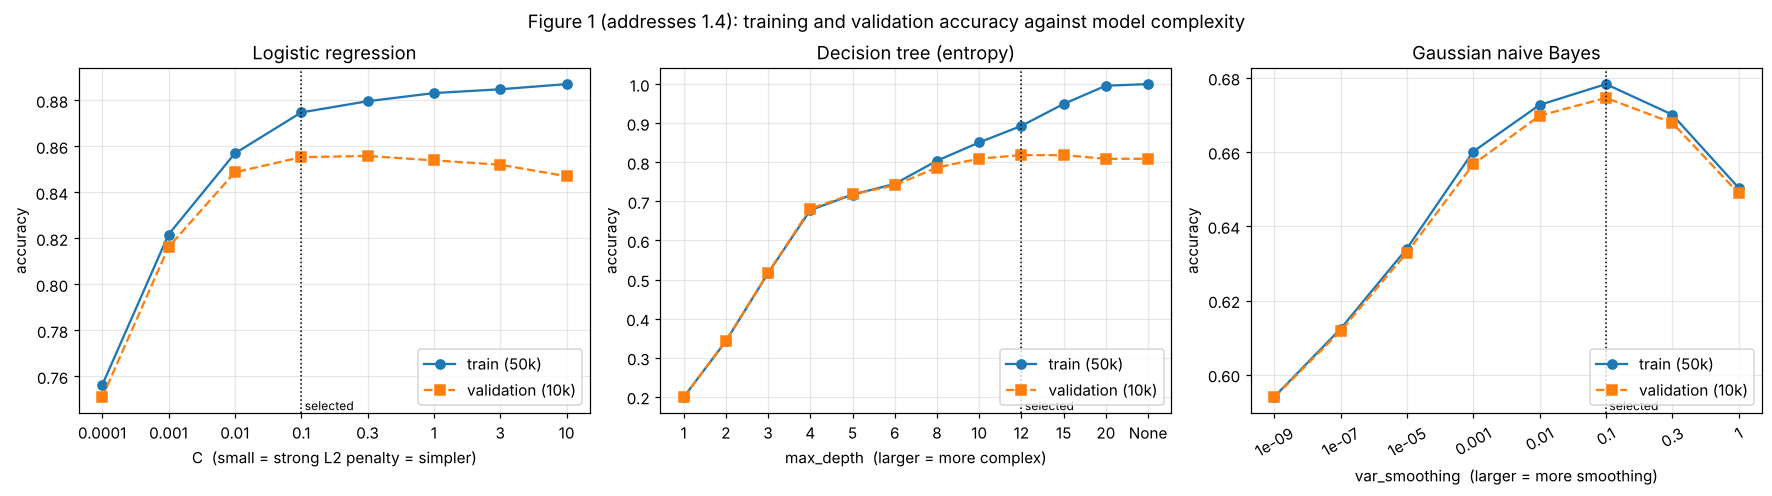

In [4]:
# ---------------- Figure 1: train vs validation across the complexity knob (addresses 1.4) -----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)

x = np.arange(len(lr_df)); ax[0].plot(x, lr_df.train_acc, "o-", label="train (50k)"); ax[0].plot(x, lr_df.val_acc, "s--", label="validation (10k)")
ax[0].set_xticks(x, [f"{c:g}" for c in lr_df.C]); ax[0].set_xlabel("C  (small = strong L2 penalty = simpler)"); ax[0].set_title("Logistic regression")
ax[0].axvline(list(lr_df.C).index(SEL["LR"]), color="k", ls=":", lw=1); ax[0].text(list(lr_df.C).index(SEL["LR"]), ax[0].get_ylim()[0], " selected", va="bottom", fontsize=8)

x = np.arange(len(dt_df)); ax[1].plot(x, dt_df.train_acc, "o-", label="train (50k)"); ax[1].plot(x, dt_df.val_acc, "s--", label="validation (10k)")
ax[1].set_xticks(x, [str(d) for d in dt_df.max_depth], rotation=0); ax[1].set_xlabel("max_depth  (larger = more complex)"); ax[1].set_title("Decision tree (entropy)")
sel_pos = [str(d) for d in dt_df.max_depth].index(str(SEL["DT"])); ax[1].axvline(sel_pos, color="k", ls=":", lw=1); ax[1].text(sel_pos, ax[1].get_ylim()[0], " selected", va="bottom", fontsize=8)

x = np.arange(len(nb_df)); ax[2].plot(x, nb_df.train_acc, "o-", label="train (50k)"); ax[2].plot(x, nb_df.val_acc, "s--", label="validation (10k)")
ax[2].set_xticks(x, [f"{v:g}" for v in nb_df.var_smoothing], rotation=30); ax[2].set_xlabel("var_smoothing  (larger = more smoothing)"); ax[2].set_title("Gaussian naive Bayes")
ax[2].axvline(list(nb_df.var_smoothing).index(SEL["NB"]), color="k", ls=":", lw=1); ax[2].text(list(nb_df.var_smoothing).index(SEL["NB"]), ax[2].get_ylim()[0], " selected", va="bottom", fontsize=8)

for a in ax: a.set_ylabel("accuracy"); a.legend(loc="lower right")
fig.suptitle("Figure 1 (addresses 1.4): training and validation accuracy against model complexity", fontsize=12)
save_fig(fig, "fig1_complexity_train_vs_val", "1.4", "Train (solid, circles) and validation (dashed, squares) accuracy against the complexity knob of each model; dotted line = value selected on validation.")
plt.show()

**Figure 1 (addresses 1.4).** Training accuracy (solid line, circles) and validation accuracy (dashed line, squares) against the complexity knob of each model. Fit on the 50,000 training images, evaluated on the same 10,000 validation images, seed 708. The dotted vertical line marks the value selected on validation.

### Interpretation of 1.4
**Logistic regression (H-LR supported).** All eight fits **converged** (n_iter from 87 to 1,019, well below the 5,000 limit; a first sweep with a 400-iteration limit was discarded because C ≥ 1 had not converged), so the differences below are properties of the models, not of unfinished optimisation. With the strongest penalty (C=0.0001) train and validation accuracy are both low (0.7562 / 0.7509, gap 0.005). Raising C raises training accuracy faster than validation accuracy: the gap is 0.019 at C=0.1, 0.029 at C=1 and 0.040 at C=10 (train 0.8870, validation 0.8470). Validation accuracy peaks at **C=0.3 (0.8558)** and is practically flat from C=0.1 to C=1 (0.8553, 0.8558, 0.8539); it then falls to 0.8520 (C=3) and 0.8470 (C=10), and validation log-loss is lowest at C=0.1 (0.4031) and rises steadily to 0.4534. The mechanism predicted from the lecture is visible: weight norm grows from 1.7 to 69.9 and the mean top-class probability from 0.52 to 0.88. The differences among C=0.1, 0.3 and 1 are far smaller than the validation sampling interval (about ±0.7 points) and should not be treated as real; the 0.9-point fall at C=10 is of the same order, so I read the trend (growing gap, rising log-loss) as the evidence of mild over-fitting, not any single pair of values. By the pre-stated rule (simplest setting within 0.1 points of the best validation accuracy) **C=0.1** is selected; it is also the log-loss minimum.

**Decision tree (H-DT supported).** Depth 1 and 2 under-fit badly (0.1985 and 0.3434 validation: 2 and 4 leaves cannot separate 10 classes). Validation accuracy rises steeply to depth 10 (0.8093), peaks at depth 12 to 15 (0.8184 / 0.8182) and then declines slightly (0.8090 at depth 20, 0.8089 unrestricted), while training accuracy rises to 0.9959 at depth 20 and 1.000 unrestricted (3,469 leaves). The train-validation gap is about 0.00 at depth 5, 0.075 at depth 12 and 0.191 unrestricted. The selected depth is **12** (the simplest within 0.1 points of the best). Seed sensitivity is tiny: three seeds give validation accuracy 0.8184, 0.8179, 0.8179 (mean 0.8181, sample std 0.0003).

**Naive Bayes (H-NB supported).** Best validation accuracy is 0.6746 at var_smoothing=0.1, far below LR; smoothing helps by about 8 points over almost none (0.5939) but does not close the gap. Its probabilities are extremely over-confident: mean top-class probability about 0.99 at 0.67 accuracy and validation log-loss about 5.0 versus 0.40 for LR. A plausible reason is that correlated pixels each add 'independent' evidence, so the evidence is counted many times; I did not test this directly.

**Limits.** One fixed split; grids are coarse; differences under about 0.5 points are not reliable.

## 1.2 Metrics: overall accuracy and a class-level view

All numbers in this section are on the **validation** set (10,000 images, 1,000 per class), for the three models with the settings selected in 1.4. They are single fits (LR and NB are deterministic; the tree's seed sensitivity is in the table above). The **support** column gives the number of images of each class, so a recall of, say, 0.80 can be read as 800 of 1,000 images; **precision** is TP divided by *all images predicted as that class* (shown too, because it has a different denominator).

In [5]:
PRED_VA = {k: timed_predict(m, Xva, k) for k, m in SEL_MODELS.items()}
n = len(yva)
rows = []
for k, p in PRED_VA.items():
    correct = int((p == yva).sum()); lo, hi = wilson_interval(correct, n)
    t = per_class_table(yva, p)
    rows.append({"model": LABEL[k], "correct / n": f"{correct} / {n}", "accuracy": correct / n, "95% interval (sampling)": f"[{lo:.4f}, {hi:.4f}]", "macro-F1": t["F1"].mean()})
overall = pd.DataFrame(rows)
overall.to_csv(RES_DIR / "overall_validation.csv", index=False)
print("Overall accuracy on VALIDATION (majority-class baseline = 0.1000, since the 10 classes are balanced)")
display(overall.style.format({"accuracy": "{:.4f}", "macro-F1": "{:.4f}"}).hide(axis="index"))

tables = {k: per_class_table(yva, p) for k, p in PRED_VA.items()}
wide = tables["LR"][["class", "support"]].copy()
for k in ["LR", "DT", "NB"]:
    wide[f"{k} recall"] = tables[k]["recall"]; wide[f"{k} precision"] = tables[k]["precision"]; wide[f"{k} F1"] = tables[k]["F1"]
wide.to_csv(RES_DIR / "per_class_validation.csv", index=False)
print("Class-level view on VALIDATION (support = images per class)")
display(wide.style.format({c: "{:.3f}" for c in wide.columns if c not in ("class", "support")}).hide(axis="index"))
for k in ["LR", "DT", "NB"]:
    log_experiment(id=f"P1-EVAL-{k}", part_task="1.2", question="Overall and per-class performance of the selected model on validation",
        hypothesis="Footwear and trousers/bags are easy; upper-body garments (shirt, T-shirt, pullover, coat) are hard.", changed_variable="model family",
        fixed_conditions="same 50k train / same 10k validation images / pixels/255", split="validation 10k", seed=SEED_NOTE, configuration=LABEL[k],
        metric="accuracy; per-class precision/recall/F1 with support", result=f"acc={overall.set_index('model').loc[LABEL[k], 'accuracy']:.4f}",
        output_path="results/part1/per_class_validation.csv", notes="single deterministic fit" if k != "DT" else "tree seed spread in tree_seeds.csv")

Overall accuracy on VALIDATION (majority-class baseline = 0.1000, since the 10 classes are balanced)


model,correct / n,accuracy,95% interval (sampling),macro-F1
Logistic regression (C=0.1),8553 / 10000,0.8553,"[0.8483, 0.8621]",0.8547
Decision tree (max_depth=12),8184 / 10000,0.8184,"[0.8107, 0.8258]",0.8168
Gaussian NB (var_smoothing=0.1),6746 / 10000,0.6746,"[0.6654, 0.6837]",0.6618


Class-level view on VALIDATION (support = images per class)


class,support,LR recall,LR precision,LR F1,DT recall,DT precision,DT F1,NB recall,NB precision,NB F1
T-shirt/top,1000,0.831,0.788,0.809,0.786,0.737,0.761,0.685,0.753,0.717
Trouser,1000,0.975,0.976,0.975,0.951,0.972,0.962,0.936,0.918,0.927
Pullover,1000,0.758,0.770,0.764,0.773,0.689,0.729,0.421,0.670,0.517
Dress,1000,0.860,0.851,0.856,0.834,0.835,0.834,0.867,0.585,0.698
Coat,1000,0.777,0.757,0.767,0.732,0.688,0.709,0.671,0.516,0.583
Sandal,1000,0.928,0.956,0.942,0.881,0.923,0.901,0.465,0.614,0.529
Shirt,1000,0.590,0.634,0.611,0.493,0.631,0.554,0.187,0.333,0.239
Sneaker,1000,0.932,0.920,0.926,0.887,0.875,0.881,0.946,0.586,0.724
Bag,1000,0.946,0.950,0.948,0.924,0.931,0.927,0.748,0.913,0.822
Ankle boot,1000,0.956,0.942,0.949,0.923,0.899,0.911,0.820,0.906,0.861


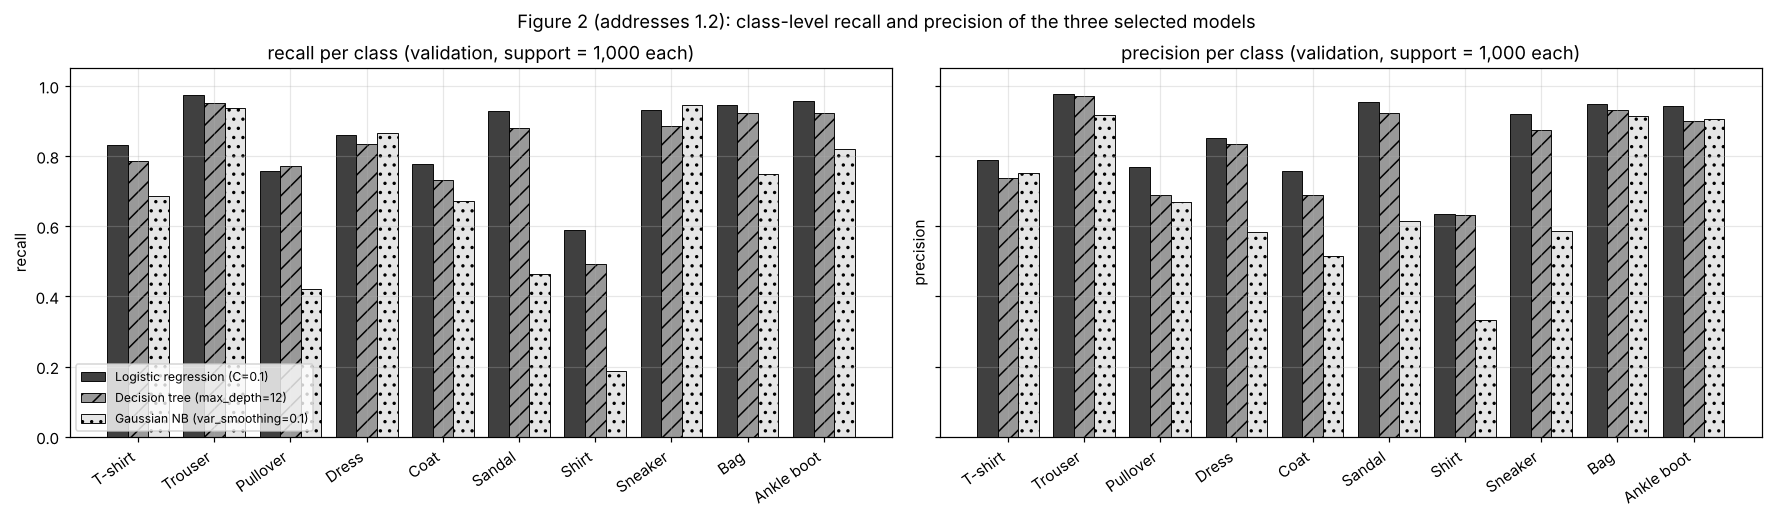

In [6]:
# ---------------- Figure 2: class-level recall and precision (addresses 1.2) -----------------
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), constrained_layout=True, sharey=True)
w = 0.27; xs = np.arange(10); hatches = {"LR": "", "DT": "//", "NB": ".."}; shade = {"LR": "0.25", "DT": "0.6", "NB": "0.9"}
for a, col in zip(ax, ["recall", "precision"]):
    for j, k in enumerate(["LR", "DT", "NB"]):
        bars = a.bar(xs + (j - 1) * w, tables[k][col], w, label=LABEL[k], hatch=hatches[k], facecolor=shade[k], edgecolor="k", lw=0.6)
    a.set_xticks(xs, SHORT, rotation=35, ha="right"); a.set_ylim(0, 1.05); a.set_title(f"{col} per class (validation, support = 1,000 each)"); a.set_ylabel(col)
ax[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure 2 (addresses 1.2): class-level recall and precision of the three selected models", fontsize=12)
save_fig(fig, "fig2_per_class_recall_precision", "1.2", "Recall and precision per class on the validation set for the three selected models (patterns distinguish the models).")
plt.show()

**Figure 2 (addresses 1.2).** Recall (left) and precision (right) per class on the 10,000 validation images (1,000 per class). Bar patterns, not colour alone, identify the model. Single fits with the settings selected in 1.4.

### Interpretation of 1.2
On validation, logistic regression (C=0.1) reaches **0.8553** accuracy (95% interval [0.8483, 0.8621]), the tree (depth 12) **0.8184** ([0.8107, 0.8258]) and naive Bayes **0.6746** ([0.6654, 0.6837]); chance is 0.10. All three are the settings selected in 1.4 on validation (not baselines). The intervals of LR and the tree do not overlap, but they describe the sampling uncertainty of one validation set; LR and the tree are compared on the same images, so this says LR is better here, not by how much on new data. The tree's seed spread (about 0.0003) is far smaller than the 3.7-point gap.

The class-level view shows that the average hides a large spread. For LR, recall ranges from 0.975 (Trouser) and 0.956 (Ankle boot) down to **0.590 for Shirt**, with Pullover 0.758 and Coat 0.777 (each class has support 1,000, so Shirt means 590 of 1,000 found). The same classes are weakest for the tree (Shirt recall 0.493, Pullover 0.773, Coat 0.732) and for NB, more extremely (Shirt recall 0.187, F1 0.24). The ordering of difficulty is therefore similar across very different models, which suggests the difficulty comes from the data (similar upper-body silhouettes) more than from one model's weakness.

Models differ in *which* error they make: NB has high recall but low precision for Dress (0.867 / 0.585) and Sneaker (0.946 / 0.586), i.e. it predicts those classes too often, while its Pullover and Sandal recall is only about 0.4 to 0.5 although these are easy for LR. Macro-F1 follows accuracy closely because the classes are exactly balanced.

## 1.3 Error analysis

**Question.** Which classes are easy or hard, which classes are confused with which, and do the two main models (logistic regression and decision tree) fail on the *same* images?

**Hypothesis.** Errors concentrate among upper-body garments with similar silhouettes (T-shirt, shirt, pullover, coat, and dress), while trousers, bags and footwear are rarely confused with other groups. Footwear errors should stay inside the footwear group.

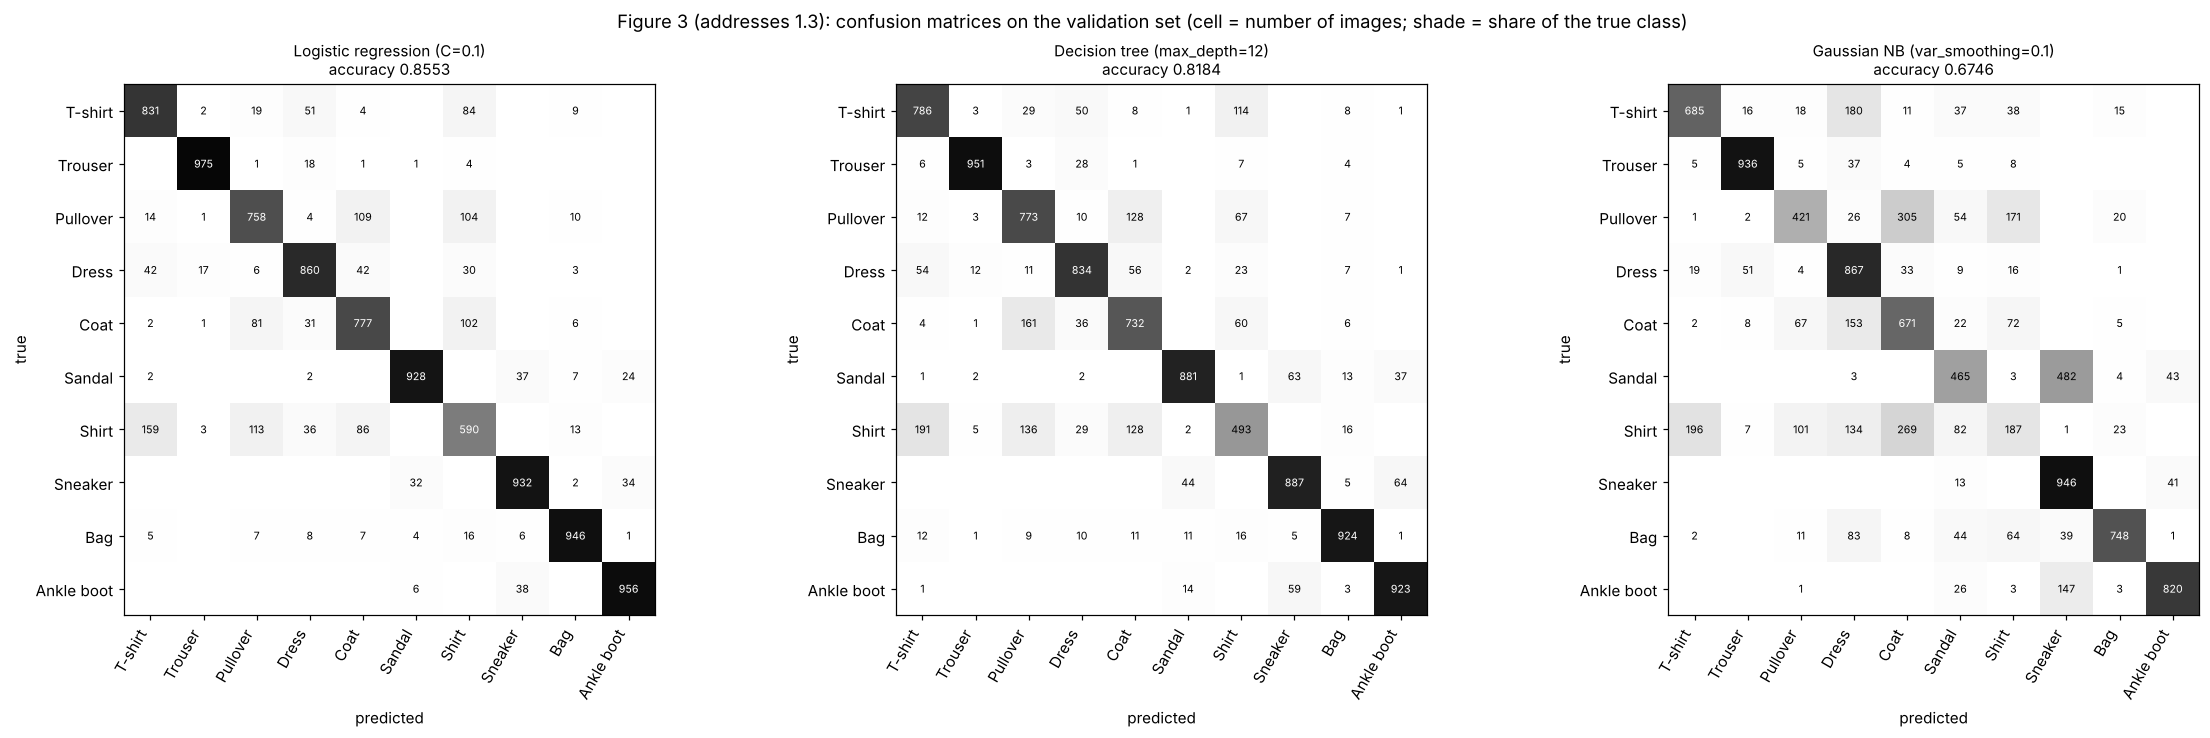

Most frequent confusions, Logistic regression (C=0.1) (validation):


true,predicted,count,share of true class
Shirt,T-shirt/top,159,0.159
Shirt,Pullover,113,0.113
Pullover,Coat,109,0.109
Pullover,Shirt,104,0.104
Coat,Shirt,102,0.102
Shirt,Coat,86,0.086


Most frequent confusions, Decision tree (max_depth=12) (validation):


true,predicted,count,share of true class
Shirt,T-shirt/top,191,0.191
Coat,Pullover,161,0.161
Shirt,Pullover,136,0.136
Pullover,Coat,128,0.128
Shirt,Coat,128,0.128
T-shirt/top,Shirt,114,0.114


Most frequent confusions, Gaussian NB (var_smoothing=0.1) (validation):


true,predicted,count,share of true class
Sandal,Sneaker,482,0.482
Pullover,Coat,305,0.305
Shirt,Coat,269,0.269
Shirt,T-shirt/top,196,0.196
T-shirt/top,Dress,180,0.180
Pullover,Shirt,171,0.171


In [7]:
# ---------------- Figure 3: row-normalised confusion matrices (addresses 1.3) -----------------
fig, ax = plt.subplots(1, 3, figsize=(21, 6.6), constrained_layout=True)
CMS = {}
for a, k in zip(ax, ["LR", "DT", "NB"]):
    cm = confusion_matrix(yva, PRED_VA[k], labels=range(10)); CMS[k] = cm
    a.imshow(cm / cm.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            v = cm[i, j]
            if v > 0: a.text(j, i, f"{v}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
    a.set_xticks(range(10), SHORT, rotation=60, ha="right"); a.set_yticks(range(10), SHORT); a.set_xlabel("predicted"); a.set_ylabel("true"); a.grid(False)
    a.set_title(f"{LABEL[k]}\naccuracy {np.trace(cm) / cm.sum():.4f}", fontsize=10)
fig.suptitle("Figure 3 (addresses 1.3): confusion matrices on the validation set (cell = number of images; shade = share of the true class)", fontsize=12)
save_fig(fig, "fig3_confusion_matrices", "1.3", "Confusion matrices (counts; shading = row-normalised share) for the three selected models on the validation set.")
plt.show()

for k in ["LR", "DT", "NB"]:
    print(f"Most frequent confusions, {LABEL[k]} (validation):")
    display(top_confusions(yva, PRED_VA[k], 6).style.format({"share of true class": "{:.3f}"}).hide(axis="index"))

Agreement of LR and tree on the SAME 10,000 validation images


,DT correct,DT wrong
LR correct,7653,531
LR wrong,900,916


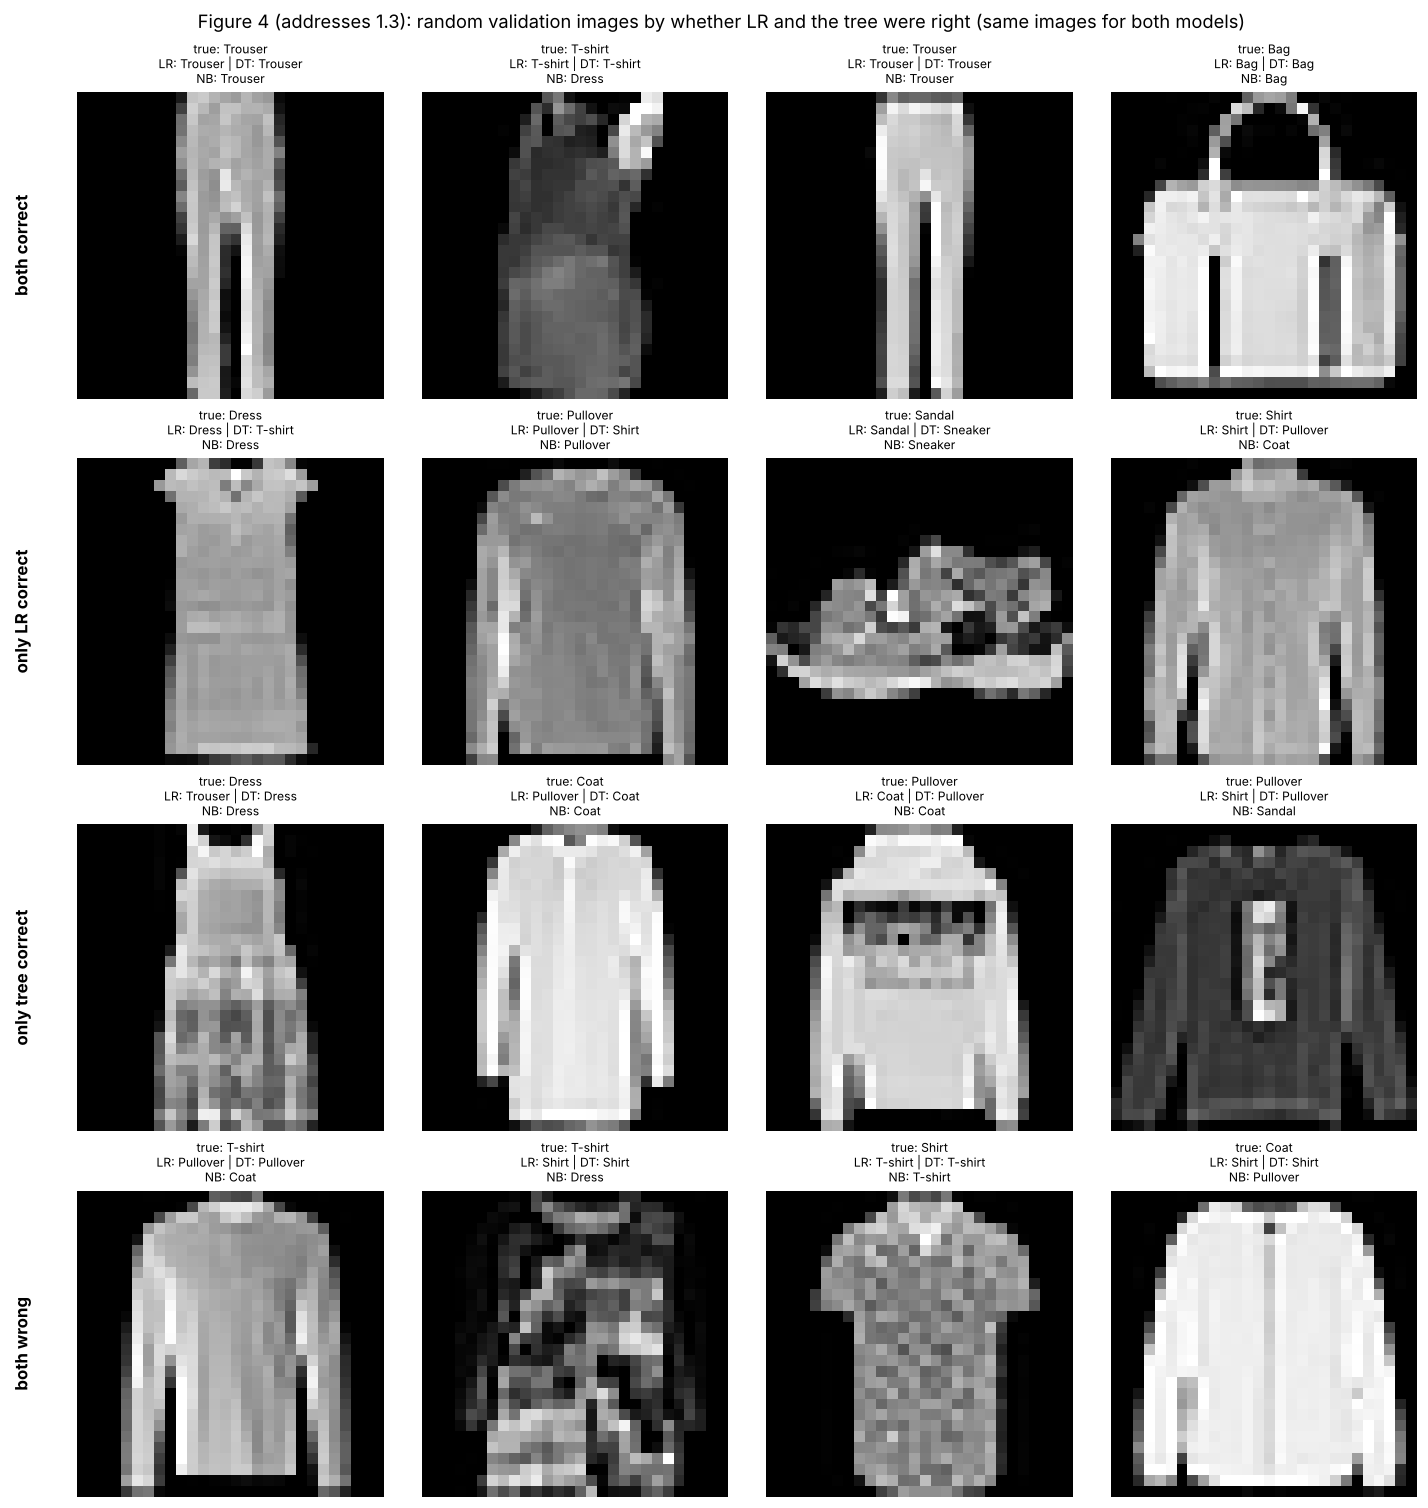

Classes from hardest to easiest (validation, mean F1 over the three models)


class,mean F1 over 3 models
Shirt,0.468
Pullover,0.670
Coat,0.687
T-shirt/top,0.762
Sandal,0.791
Dress,0.796
Sneaker,0.843
Bag,0.899
Ankle boot,0.907
Trouser,0.955


In [8]:
# ---------------- Same images, two models: agreement table and a fixed random example grid (addresses 1.3) -----------------
lr_ok = PRED_VA["LR"] == yva; dt_ok = PRED_VA["DT"] == yva
agree = pd.DataFrame({"DT correct": [int((lr_ok & dt_ok).sum()), int((lr_ok & ~dt_ok).sum())],
                      "DT wrong":   [int((~lr_ok & dt_ok).sum()), int((~lr_ok & ~dt_ok).sum())]}, index=["LR correct", "LR wrong"])
print("Agreement of LR and tree on the SAME 10,000 validation images"); display(agree)
log_experiment(id="P1-ERR-01", part_task="1.3", question="Do LR and the tree fail on the same validation images?",
    hypothesis="Largely the same hard classes, but different individual images, because the models use pixels differently.", changed_variable="model family",
    fixed_conditions="identical validation images", split="validation 10k", seed=SEED_NOTE, configuration=f"{LABEL['LR']} vs {LABEL['DT']}",
    metric="2x2 agreement counts", result=agree.to_dict(), output_path="results/part1/agreement_lr_dt.csv", notes="")
agree.to_csv(RES_DIR / "agreement_lr_dt.csv")

rng = np.random.default_rng(SEED)           # fixed seed: images are drawn at random, not hand-picked
groups = {"both correct": np.flatnonzero(lr_ok & dt_ok), "only LR correct": np.flatnonzero(lr_ok & ~dt_ok),
          "only tree correct": np.flatnonzero(~lr_ok & dt_ok), "both wrong": np.flatnonzero(~lr_ok & ~dt_ok)}
fig, ax = plt.subplots(4, 4, figsize=(13, 13.6), constrained_layout=True)
for r, (g, idx) in enumerate(groups.items()):
    chosen = rng.choice(idx, size=min(4, len(idx)), replace=False)
    for c in range(4):
        a = ax[r, c]; a.axis("off")
        if c < len(chosen):
            i = chosen[c]; a.imshow(Xva[i].reshape(28, 28), cmap="gray")
            a.set_title(f"true: {SHORT[yva[i]]}\nLR: {SHORT[PRED_VA['LR'][i]]} | DT: {SHORT[PRED_VA['DT'][i]]}\nNB: {SHORT[PRED_VA['NB'][i]]}", fontsize=8)
    ax[r, 0].text(-0.15, 0.5, g, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
fig.suptitle("Figure 4 (addresses 1.3): random validation images by whether LR and the tree were right (same images for both models)", fontsize=12)
save_fig(fig, "fig4_error_examples", "1.3", "Four randomly drawn validation images (seed 708) per agreement group; titles give the true class and the predictions of LR, tree and NB.")
plt.show()

rank = wide[["class"]].copy(); rank["mean F1 over 3 models"] = wide[["LR F1", "DT F1", "NB F1"]].mean(axis=1); rank = rank.sort_values("mean F1 over 3 models")
print("Classes from hardest to easiest (validation, mean F1 over the three models)"); display(rank.style.format({"mean F1 over 3 models": "{:.3f}"}).hide(axis="index"))

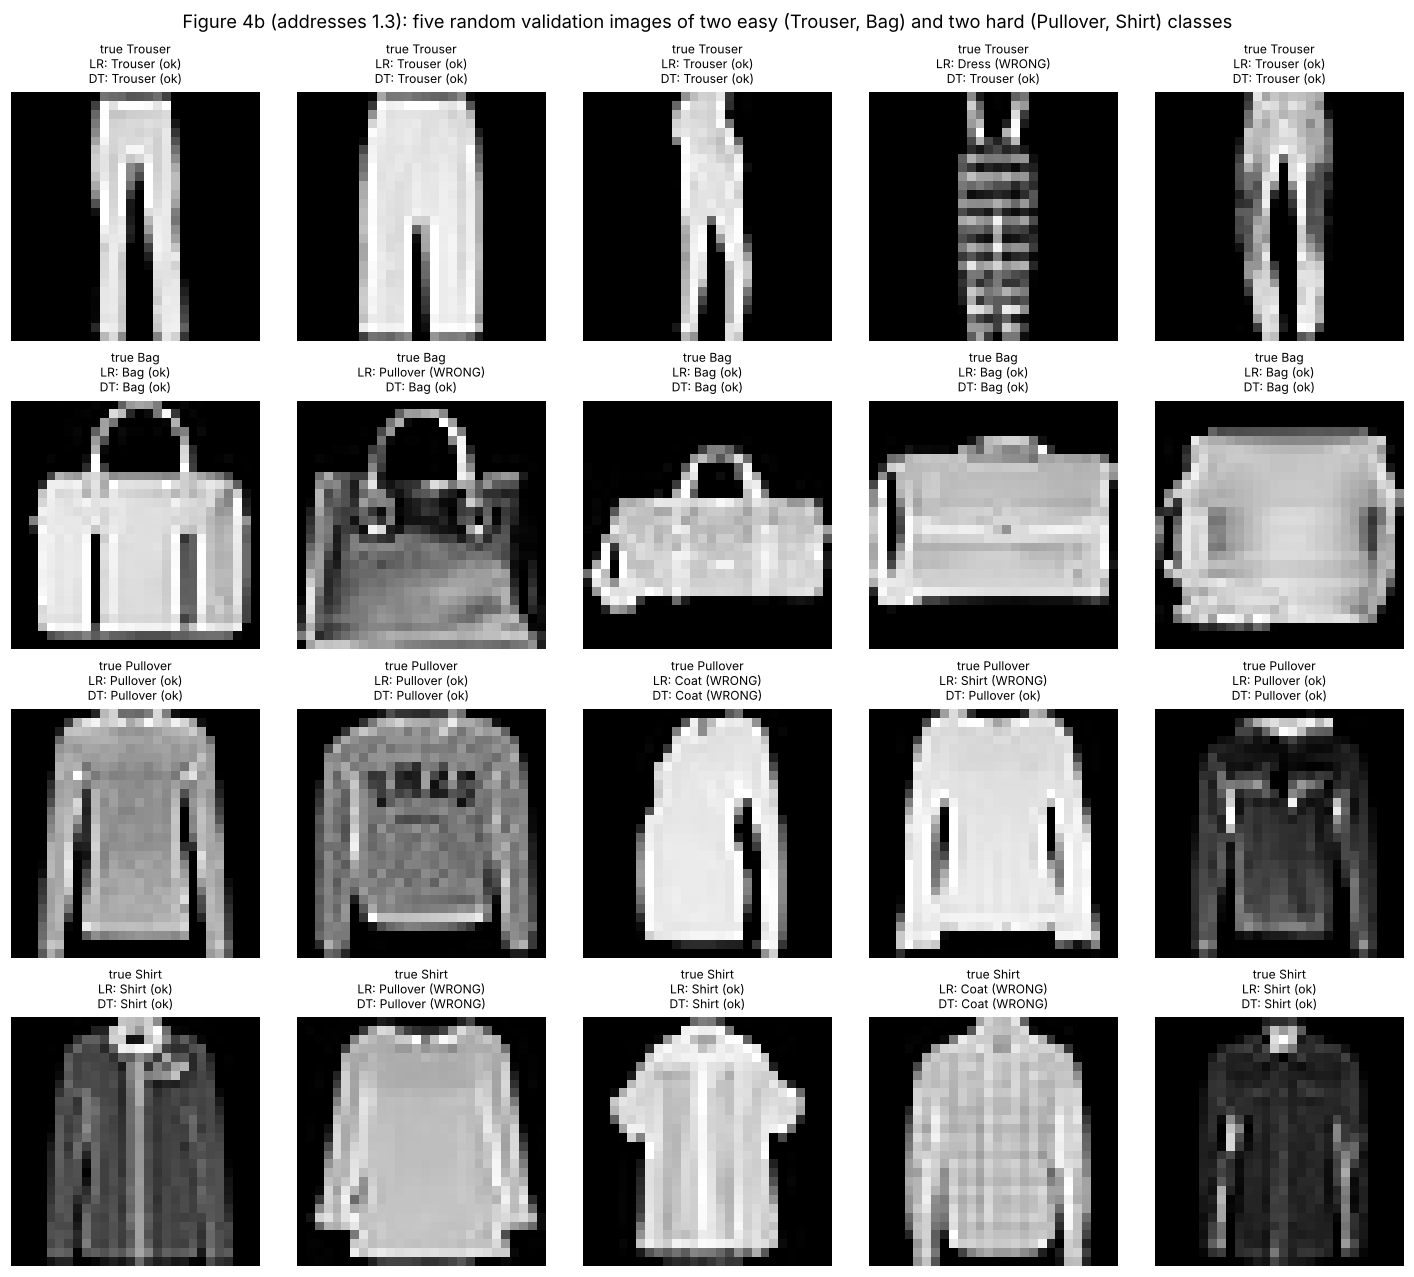

In [9]:
# ---------------- Figure 4b: easy and hard classes side by side, random validation images of ONE class each (addresses 1.3) -----------------
rng2 = np.random.default_rng(SEED + 1)                       # seeded sample, same images shown for every model
focus = [("Trouser", 1), ("Bag", 8), ("Pullover", 2), ("Shirt", 6)]       # two easy and two hard classes (by the F1 ranking above)
fig, ax = plt.subplots(4, 5, figsize=(13, 11.5), constrained_layout=True)
for r, (nm, c) in enumerate(focus):
    for j, i in enumerate(rng2.choice(np.flatnonzero(yva == c), 5, replace=False)):
        a = ax[r, j]; a.imshow(Xva[i].reshape(28, 28), cmap="gray"); a.axis("off")
        ok = lambda k: "ok" if PRED_VA[k][i] == yva[i] else "WRONG"
        a.set_title(f"true {nm}\nLR: {SHORT[PRED_VA['LR'][i]]} ({ok('LR')})\nDT: {SHORT[PRED_VA['DT'][i]]} ({ok('DT')})", fontsize=8)
fig.suptitle("Figure 4b (addresses 1.3): five random validation images of two easy (Trouser, Bag) and two hard (Pullover, Shirt) classes", fontsize=12)
save_fig(fig, "fig4b_easy_vs_hard_classes", "1.3", "Five seeded random validation images for each of two easy and two hard classes, with LR and tree predictions.")
plt.show()

**Figure 4 (addresses 1.3).** Four validation images drawn at random (seed 708, not hand-picked) from each of four groups defined by whether logistic regression and the tree were right. Both models are shown the same images. The third line of each title gives the naive Bayes prediction.

### Interpretation of 1.3
**Where errors concentrate (hypothesis supported).** By mean F1 over the three models the hardest classes are Shirt (0.468), Pullover (0.670) and Coat (0.687) and the easiest are Trouser (0.955), Ankle boot (0.907) and Bag (0.899). The most frequent LR confusions all lie inside the upper-body group: Shirt predicted as T-shirt (159 of 1,000), Shirt as Pullover (113), Pullover as Coat (109), Pullover as Shirt (104), Coat as Shirt (102), Shirt as Coat (86). The tree's top confusions are the same pairs (Shirt to T-shirt 191, Coat to Pullover 161, Shirt to Pullover 136), only larger. Footwear errors stay mostly inside the footwear group for LR and the tree (visible in Figure 3).

**Same images or not?** On the same 10,000 validation images LR and the tree are both right on 7,653, both wrong on 916, only LR right on 900 and only the tree right on 531. So about half of the tree's 1,816 errors (916) are shared with LR: the models fail in the same hard regions, but not on the same individual images.

**Easy and hard classes in pictures (Figure 4b, five seeded random images per class, an illustration, not a statistic).** For the easy classes Trouser and Bag, 8 of the 10 shown images are classified correctly by both models; the two LR errors are unusual instances (striped dungarees-like trousers predicted as Dress; a bag with open straps predicted as Pullover), where the tree was right. For the hard classes, Pullover is correct in 3 of 5 for LR and 4 of 5 for the tree, and Shirt in 3 of 5 for both. The wrong cases are plain long-sleeved tops predicted as Pullover or Coat, which look similar in silhouette. With five images per class I draw no quantitative conclusion from these pictures; the numbers above carry the claim.

**What this suggests.** Upper-body garments differ in fine texture, sleeve length and collar shape that raw pixels and a linear or axis-aligned model capture poorly. This is a hypothesis about the representation, not something these experiments test directly (Parts 3 to 5 examine it).

## 1.5 Decisions and costs: a binary problem of our own

**Problem (derived from the ten classes).** *Shirt versus everything else.* Imagine an online shop that files each photographed garment into a category automatically. A photo predicted as **Shirt** goes into the Shirts listing.

* **Positive** = Shirt (class 6); **negative** = the other nine classes. On validation this is 1,000 positives and 9,000 negatives, so **prevalence is 10%**. Always predicting "not a shirt" is therefore already 90% accurate and useless, the lecture's imbalanced-data warning, so accuracy alone is not an adequate metric here.
* **Two errors with different costs.** A *false negative* (a shirt is hidden in the wrong listing) loses a sale; a *false positive* (something else appears among the shirts) causes complaints and returns. The costs below are **illustrative assumptions, not measured data**. Costs are in arbitrary units per item; correct decisions cost 0.

| Scenario | Cost of a false negative | Cost of a false positive |
|---|---|---|
| A: balanced | 1 | 1 |
| B: a missed shirt is 5× worse | 5 | 1 |
| C: a false alarm is 5× worse | 1 | 5 |

**Score and threshold.** Each model's score for this problem is its predicted probability of class *Shirt* (the probability mass the multi-class model assigns to that class); an image is flagged as Shirt if the score is at least a threshold *t*. Lowering *t* flags more images: fewer false negatives, more false positives. The default is *t* = 0.5. (The tree's score is the training-class proportion in its leaf, so it takes few distinct values; naive Bayes probabilities are typically over-confident.)

**Hypotheses.** (i) The ROC curves of the three models differ, with LR the best; (ii) the cost-minimising threshold moves **down** when missed shirts are costlier (B) and **up** when false alarms are costlier (C); (iii) if LR's probabilities were well calibrated, the optimal threshold would be close to *c<sub>FP</sub> / (c<sub>FP</sub> + c<sub>FN</sub>)*, i.e. 0.5, 0.167 and 0.833 for A, B and C.

**Rule R1:** the thresholds are chosen on the validation images only. **Metric:** TPR, FPR, precision, ROC AUC, and expected cost per item on validation.

In [10]:
SHIRT = CLASS_NAMES.index("Shirt"); y_bin = (yva == SHIRT).astype(int); N = len(y_bin); prev = y_bin.mean()
SCORES = {k: m.predict_proba(Xva)[:, SHIRT] for k, m in SEL_MODELS.items()}
SCEN = {"A: balanced (FN 1, FP 1)": (1, 1), "B: missed shirt 5x worse (FN 5, FP 1)": (5, 1), "C: false alarm 5x worse (FN 1, FP 5)": (1, 5)}
TS = np.linspace(0, 1, 1001)

def counts_at(score, t):
    pred = score >= t
    return int((pred & (y_bin == 1)).sum()), int((pred & (y_bin == 0)).sum()), int((~pred & (y_bin == 1)).sum()), int((~pred & (y_bin == 0)).sum())  # TP FP FN TN

CURVE = {k: np.array([counts_at(s, t) for t in TS]) for k, s in SCORES.items()}   # columns TP FP FN TN for every threshold
def cost_curve(k, cfn, cfp): c = CURVE[k]; return (cfn * c[:, 2] + cfp * c[:, 1]) / N

# ---- ROC / AUC on validation
ROC = {k: roc_curve(y_bin, s) for k, s in SCORES.items()}; AUC = {k: roc_auc_score(y_bin, s) for k, s in SCORES.items()}
print("Shirt-vs-rest, validation: prevalence", prev, "| 'never shirt' accuracy", 1 - prev)
print("ROC AUC:", {LABEL[k]: round(v, 4) for k, v in AUC.items()})

# ---- LR at a few thresholds
rows = []
for t in [0.05, 0.1, 0.167, 0.2, 0.3, 0.5, 0.7, 0.833, 0.9]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    rows.append({"threshold": t, "TP": TP, "FP": FP, "FN": FN, "TN": TN, "TPR (recall)": TP / (TP + FN), "FPR": FP / (FP + TN),
                 "precision": TP / max(TP + FP, 1), "accuracy": (TP + TN) / N})
thr_table = pd.DataFrame(rows); thr_table.to_csv(RES_DIR / "shirt_threshold_table_lr.csv", index=False)
print("Logistic regression: confusion counts and rates at several thresholds (validation)")
display(thr_table.style.format({"threshold": "{:.3f}", "TPR (recall)": "{:.3f}", "FPR": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.4f}"}).hide(axis="index"))

# ---- cost-minimising thresholds on validation
rows = []; BEST_T = {}
for sname, (cfn, cfp) in SCEN.items():
    for k in ["LR", "DT", "NB"]:
        cc = cost_curve(k, cfn, cfp); j = int(np.argmin(cc)); t_star = float(TS[j])
        if k == "LR": BEST_T[sname] = t_star
        rows.append({"scenario": sname, "model": k, "best threshold": t_star, "expected cost @ best": cc[j], "expected cost @ 0.5": cc[500],
                     "never-shirt baseline": cfn * prev, "calibrated-theory threshold": cfp / (cfp + cfn)})
cost_table = pd.DataFrame(rows); cost_table.to_csv(RES_DIR / "shirt_cost_table.csv", index=False)
print("Expected cost per item on validation (lower is better)")
display(cost_table.style.format({"best threshold": "{:.3f}", "expected cost @ best": "{:.4f}", "expected cost @ 0.5": "{:.4f}", "never-shirt baseline": "{:.4f}", "calibrated-theory threshold": "{:.3f}"}).hide(axis="index"))
for sname in SCEN:
    log_experiment(id=f"P1-THR-{sname[0]}", part_task="1.5", question="How does the decision threshold trade false negatives against false positives, and where is the cost minimum?",
        hypothesis="Optimal threshold moves down when FN is costlier and up when FP is costlier; near cFP/(cFP+cFN) if calibrated.", changed_variable="decision threshold (and cost ratio)",
        fixed_conditions="Shirt-vs-rest from selected LR scores; same validation images", split="validation 10k", seed=SEED_NOTE, configuration=sname,
        metric="expected cost per item; TPR/FPR", result=f"best threshold (LR) = {BEST_T[sname]:.3f}", output_path="results/part1/shirt_cost_table.csv", notes="costs are illustrative assumptions")

Shirt-vs-rest, validation: prevalence 0.1 | 'never shirt' accuracy 0.9
ROC AUC: {'Logistic regression (C=0.1)': 0.9435, 'Decision tree (max_depth=12)': 0.8831, 'Gaussian NB (var_smoothing=0.1)': 0.6944}
Logistic regression: confusion counts and rates at several thresholds (validation)


threshold,TP,FP,FN,TN,TPR (recall),FPR,precision,accuracy
0.050,944,2055,56,6945,0.944,0.228,0.315,0.7889
0.100,889,1418,111,7582,0.889,0.158,0.385,0.8471
0.167,824,970,176,8030,0.824,0.108,0.459,0.8854
0.200,793,829,207,8171,0.793,0.092,0.489,0.8964
0.300,699,530,301,8470,0.699,0.059,0.569,0.9169
0.500,525,230,475,8770,0.525,0.026,0.695,0.9295
0.700,339,71,661,8929,0.339,0.008,0.827,0.9268
0.833,174,17,826,8983,0.174,0.002,0.911,0.9157
0.900,69,7,931,8993,0.069,0.001,0.908,0.9062


Expected cost per item on validation (lower is better)


scenario,model,best threshold,expected cost @ best,expected cost @ 0.5,never-shirt baseline,calibrated-theory threshold
"A: balanced (FN 1, FP 1)",LR,0.580,0.0692,0.0705,0.1000,0.500
"A: balanced (FN 1, FP 1)",DT,0.601,0.0754,0.0790,0.1000,0.500
"A: balanced (FN 1, FP 1)",NB,1.000,0.1140,0.1189,0.1000,0.500
"B: missed shirt 5x worse (FN 5, FP 1)",LR,0.164,0.1841,0.2605,0.5000,0.167
"B: missed shirt 5x worse (FN 5, FP 1)",DT,0.196,0.2118,0.2922,0.5000,0.167
"B: missed shirt 5x worse (FN 5, FP 1)",NB,0.001,0.4400,0.4441,0.5000,0.167
"C: false alarm 5x worse (FN 1, FP 5)",LR,0.838,0.0902,0.1625,0.1000,0.833
"C: false alarm 5x worse (FN 1, FP 5)",DT,0.924,0.1117,0.1818,0.1000,0.833
"C: false alarm 5x worse (FN 1, FP 5)",NB,1.000,0.2336,0.2693,0.1000,0.833


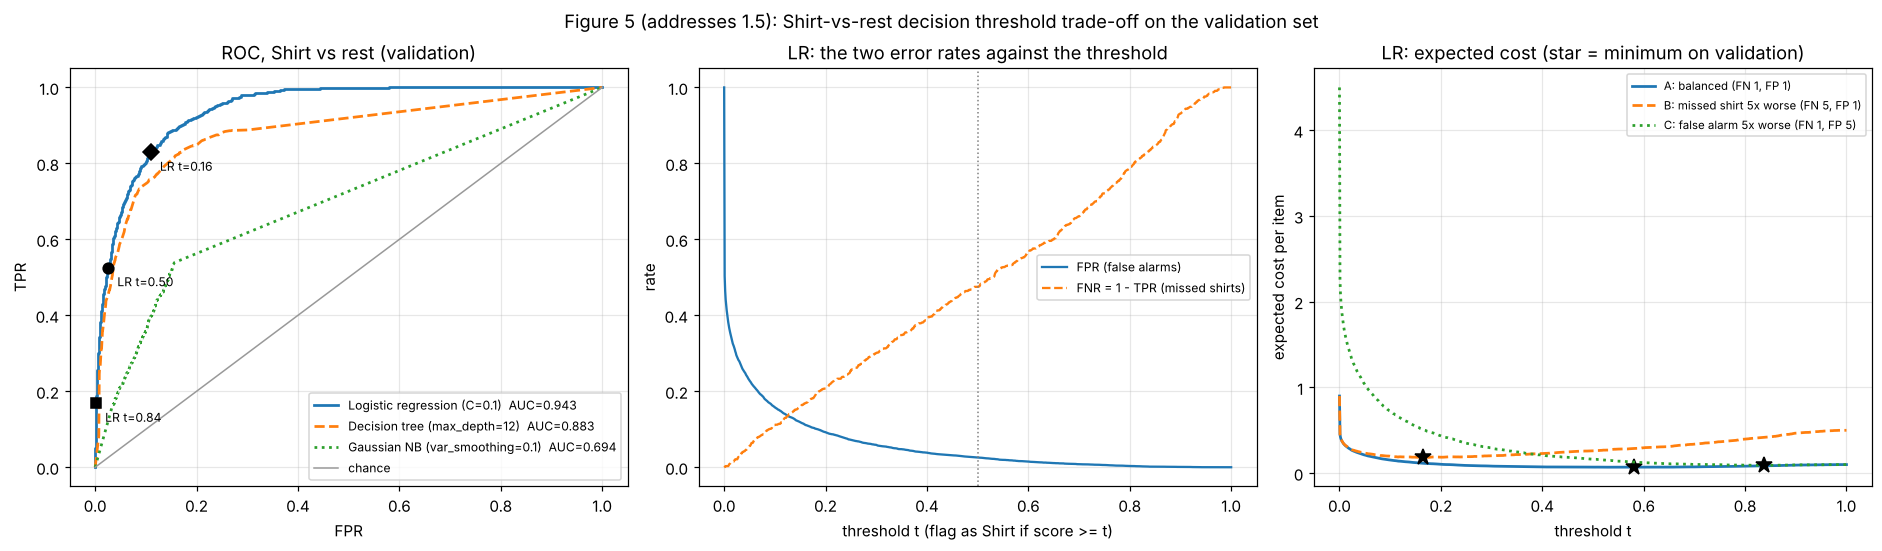

LR, scenario A: balanced (FN 1, FP 1): threshold 0.580 -> TP 455, FP 147, FN 545, TN 8853  (TPR 0.455, FPR 0.016, precision 0.756)
LR, scenario B: missed shirt 5x worse (FN 5, FP 1): threshold 0.164 -> TP 829, FP 986, FN 171, TN 8014  (TPR 0.829, FPR 0.110, precision 0.457)
LR, scenario C: false alarm 5x worse (FN 1, FP 5): threshold 0.838 -> TP 168, FP 14, FN 832, TN 8986  (TPR 0.168, FPR 0.002, precision 0.923)


In [11]:
# ---------------- Figure 5: ROC and threshold trade-off on validation (addresses 1.5) -----------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), constrained_layout=True)
styles = {"LR": ("-", "o"), "DT": ("--", "s"), "NB": (":", "^")}
for k in ["LR", "DT", "NB"]:
    f, tpr, _ = ROC[k]; ax[0].plot(f, tpr, ls=styles[k][0], lw=1.8, label=f"{LABEL[k]}  AUC={AUC[k]:.3f}")
ax[0].plot([0, 1], [0, 1], color="0.6", lw=1, label="chance")
for t, mk in [(0.5, "o"), (BEST_T["B: missed shirt 5x worse (FN 5, FP 1)"], "D"), (BEST_T["C: false alarm 5x worse (FN 1, FP 5)"], "s")]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t); ax[0].plot(FP / (FP + TN), TP / (TP + FN), mk, color="k", ms=7); ax[0].annotate(f"LR t={t:.2f}", (FP / (FP + TN), TP / (TP + FN)), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC, Shirt vs rest (validation)"); ax[0].legend(loc="lower right", fontsize=8)

c = CURVE["LR"]; ax[1].plot(TS, c[:, 1] / (c[:, 1] + c[:, 3]), "-", label="FPR (false alarms)"); ax[1].plot(TS, c[:, 2] / (c[:, 0] + c[:, 2]), "--", label="FNR = 1 - TPR (missed shirts)")
ax[1].axvline(0.5, color="0.5", lw=1, ls=":"); ax[1].set_xlabel("threshold t (flag as Shirt if score >= t)"); ax[1].set_ylabel("rate"); ax[1].set_title("LR: the two error rates against the threshold"); ax[1].legend(fontsize=8)

for (sname, (cfn, cfp)), ls in zip(SCEN.items(), ["-", "--", ":"]):
    cc = cost_curve("LR", cfn, cfp); ax[2].plot(TS, cc, ls=ls, lw=1.8, label=sname); j = int(np.argmin(cc)); ax[2].plot(TS[j], cc[j], "k*", ms=11)
ax[2].set_xlabel("threshold t"); ax[2].set_ylabel("expected cost per item"); ax[2].set_title("LR: expected cost (star = minimum on validation)"); ax[2].legend(fontsize=7.5)
fig.suptitle("Figure 5 (addresses 1.5): Shirt-vs-rest decision threshold trade-off on the validation set", fontsize=12)
save_fig(fig, "fig5_threshold_tradeoff", "1.5", "ROC curves of the three models; LR error rates against threshold; LR expected cost per item against threshold for three cost scenarios (validation).")
plt.show()

for sname, t in BEST_T.items():
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    print(f"LR, scenario {sname}: threshold {t:.3f} -> TP {TP}, FP {FP}, FN {FN}, TN {TN}  (TPR {TP/(TP+FN):.3f}, FPR {FP/(FP+TN):.3f}, precision {TP/max(TP+FP,1):.3f})")

In [12]:
# ---------------- Calibration check of the LR Shirt score (supports the 'calibrated' hypothesis iii) -----------------
bins = np.array([0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0001]); b = np.digitize(SCORES["LR"], bins) - 1
cal = pd.DataFrame({"score bin": [f"[{bins[i]:.2f}, {min(bins[i+1], 1):.2f})" for i in range(len(bins) - 1)],
                    "n images": [int((b == i).sum()) for i in range(len(bins) - 1)],
                    "mean predicted P(Shirt)": [SCORES["LR"][b == i].mean() if (b == i).any() else np.nan for i in range(len(bins) - 1)],
                    "observed share of Shirts": [y_bin[b == i].mean() if (b == i).any() else np.nan for i in range(len(bins) - 1)]})
cal.to_csv(RES_DIR / "shirt_calibration_lr.csv", index=False)
print("LR calibration on validation: if the probabilities were calibrated the last two columns would agree"); display(cal.style.format({"mean predicted P(Shirt)": "{:.3f}", "observed share of Shirts": "{:.3f}"}).hide(axis="index"))

# ---------------- Chosen operating point (primary scenario B), chosen on VALIDATION and frozen -----------------
PRIMARY = "B: missed shirt 5x worse (FN 5, FP 1)"; T_OP = BEST_T[PRIMARY]; cfn, cfp = SCEN[PRIMARY]
rows = []
for name, t in [("LR, default t = 0.5", 0.5), (f"LR, chosen operating point t = {T_OP:.3f}", T_OP)]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    rows.append({"decision rule": name, "TP": TP, "FP": FP, "FN": FN, "TN": TN, "TPR": TP / (TP + FN), "FPR": FP / (FP + TN), "precision": TP / max(TP + FP, 1), "accuracy": (TP + TN) / N, f"cost/item (B)": (cfn * FN + cfp * FP) / N})
rows.insert(0, {"decision rule": "never flag Shirt", "TP": 0, "FP": 0, "FN": int(y_bin.sum()), "TN": int((1 - y_bin).sum()), "TPR": 0.0, "FPR": 0.0, "precision": np.nan, "accuracy": 1 - prev, "cost/item (B)": cfn * prev})
op = pd.DataFrame(rows); op.to_csv(RES_DIR / "shirt_operating_point.csv", index=False)
print(f"Operating point for scenario B (validation, 1,000 Shirts / 9,000 others):"); display(op.style.format({"TPR": "{:.3f}", "FPR": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.4f}", "cost/item (B)": "{:.4f}"}).hide(axis="index"))

LR calibration on validation: if the probabilities were calibrated the last two columns would agree


score bin,n images,mean predicted P(Shirt),observed share of Shirts
"[0.00, 0.05)",7001,0.006,0.008
"[0.05, 0.10)",692,0.072,0.079
"[0.10, 0.20)",685,0.145,0.140
"[0.20, 0.30)",393,0.245,0.239
"[0.30, 0.50)",474,0.388,0.367
"[0.50, 0.70)",345,0.595,0.539
"[0.70, 0.90)",334,0.802,0.808
"[0.90, 1.00)",76,0.938,0.908


Operating point for scenario B (validation, 1,000 Shirts / 9,000 others):


decision rule,TP,FP,FN,TN,TPR,FPR,precision,accuracy,cost/item (B)
never flag Shirt,0,0,1000,9000,0.000,0.000,nan,0.9000,0.5000
"LR, default t = 0.5",525,230,475,8770,0.525,0.026,0.695,0.9295,0.2605
"LR, chosen operating point t = 0.164",829,986,171,8014,0.829,0.110,0.457,0.8843,0.1841


**Chosen operating point (1.5).** I take **scenario B** (a missed shirt costs 5 times a wrong flag) as the primary one, with the **logistic-regression score and the threshold that minimises validation cost** (printed above and frozen in the test plan below). *Justification (an assumption, not data):* the listing's purpose is to sell shirts; a shirt filed in the wrong category is never found, whereas a wrong item among the shirts is cheap to correct with a quick review. If the real cost ratio were different, the cost table above gives the matching threshold for scenarios A and C. The decision is made on validation images only and is not changed after any test result.

**Figure 5 (addresses 1.5).** Left: ROC curves for the Shirt-versus-rest decision on the validation images (line styles identify the models; black markers show logistic-regression operating points at *t* = 0.5 and at the cost-optimal thresholds of scenarios B and C). Middle: logistic regression's false-positive and false-negative rates against the threshold. Right: expected cost per item against the threshold for the three cost scenarios; stars mark the minimum. All validation data, selected models, seed 708.

### Interpretation of 1.5
**Baseline and metric.** With 10% Shirts, 'never Shirt' is 90% accurate (cost 0.100 in scenario A), and LR's accuracy at t=0.5 is 0.9295. Accuracy barely separates a useful filter from a trivial one, so I report TPR, FPR, precision and expected cost on 1,001 thresholds (the LR table lists nine of them).

**Ranking of models (hypothesis i supported).** ROC AUC for Shirt-vs-rest on validation is **0.944 for LR, 0.883 for the tree and 0.694 for NB**. The tree's score is a leaf proportion and NB's is extremely over-confident, so neither is treated as a calibrated probability; their thresholds are meaningful only on the validation set. NB's best expected-cost threshold lies at the end of the range: in scenario A it is no better than 'never Shirt' (0.1140 versus 0.100) and in scenario C worse (0.2336 versus 0.100). LR beats 'never Shirt' in A (0.0692 versus 0.100), B (0.1841 versus 0.500) and, by a small margin, C (0.0902 versus 0.100); at t=0.5 in C it is worse than the baseline (0.1625 versus 0.100).

**Threshold trade-off.** For LR, lowering t from 0.5 to 0.1 raises TPR from 0.525 to 0.889, but also FPR from 0.026 to 0.158 and lowers precision from 0.695 to 0.385: the two errors trade directly. At t=0.5 the filter misses 475 of 1,000 shirts.

**Cost-dependent threshold (hypothesis ii supported).** The cost-minimising LR threshold on validation is 0.580 for A, **0.164 for B** and **0.838 for C**: it moves down when misses are costly and up when false alarms are costly. At t=0.5 the expected cost would be 0.2605 in B and 0.1625 in C versus 0.1841 and 0.0902 at the best threshold.

**Chosen operating point.** Scenario B, LR, t=0.164: it finds 829 of 1,000 shirts (TPR 0.829) at the price of 986 false flags (FPR 0.110, precision 0.457), cost 0.1841 per item versus 0.2605 at the default threshold and 0.5000 for 'never Shirt'. Overall accuracy falls to 0.8843, which is why accuracy is not the criterion here.

**Calibration (hypothesis iii supported, approximately).** The optimal thresholds (0.164, 0.838, 0.580) are close to the calibrated-theory values 0.167, 0.833, 0.500, and the calibration table agrees: in the eight score bins the mean predicted P(Shirt) and the observed share of Shirts differ by at most 0.06, with the largest gaps in the 0.5 to 0.7 bin (0.595 predicted, 0.539 observed) and the 0.9 to 1.0 bin (0.938 versus 0.908), i.e. slight over-confidence at high scores. For the tree the optimal thresholds are further from theory (0.196, 0.924, 0.601).

**Caveats.** The costs are assumptions for illustration. The thresholds are tuned and evaluated on the same validation images, so the stated costs are slightly optimistic; the test set will be evaluated once, with the frozen thresholds.

## Part 1 summary and evidence index

| Task | Evidence in this notebook |
|---|---|
| 1.1 | Model table and justification; sweep tables |
| 1.2 | Overall accuracy table with intervals; class-level table with supports; Figure 2 |
| 1.3 | Figure 3 (confusion matrices), Figure 4 (same images, both models), agreement table, hardest-to-easiest ranking |
| 1.4 | Sweep tables for the three models; Figure 1; tree seed table |
| 1.5 | ROC and threshold tables; cost table; Figure 5 |

### Limitations of Part 1
* One fixed split (seed 708) and a single validation set: differences below about 0.5 points are not reliable, and several validation differences (for example among LR with C between 0.1 and 1) are within the sampling interval.
* Grids are coarse; the selection rule (simplest within 0.1 points) is a convention fixed before the formal runs.
* Only the tree has seed variability measured; LR and naive Bayes are deterministic, so no variability across training randomness exists for them, but variability across different data splits is not measured.
* The Shirt-vs-rest costs are illustrative assumptions, and thresholds are tuned and evaluated on the same validation data.
* The example images (Figures 4 and 4b) are small seeded samples used as illustrations.
* The first LR sweep (400 iterations) was discarded because it had not converged for C at or above 1; it is mentioned in the design disclosure and is not part of the results.
* No test data has been used.

## Frozen test plan for Part 1 (rules R6, R7)

The next cell records, **before any test image is used**, exactly what will be evaluated on the sealed test set: the three models with the settings selected above (already fitted on the 50,000 training images, never refitted), the metrics, and the Shirt-versus-rest thresholds chosen on validation. The plan is written to `results/test_plan_part1.json`; if the file already exists it is *checked, not overwritten*, so the plan cannot drift after seeing results. The test evaluation itself is guarded by `RUN_FINAL_TEST` and is only to be switched on **once, after all parts are finished**; ideas prompted by test errors would be future hypotheses, not validated improvements (R7).

In [13]:
test_plan = {
    "part": 1, "split": "official test set (10,000 images, sealed until RUN_FINAL_TEST=True)", "fit_data": "train 50,000 (no refit)",
    "models": {"logistic_regression": {"C": SEL["LR"], "max_iter": LR_MAXIT, "seed": "deterministic"},
               "decision_tree": {"criterion": "entropy", "max_depth": SEL["DT"], "random_state": SEED},
               "gaussian_nb": {"var_smoothing": SEL["NB"]}},
    "metrics": ["overall accuracy with 95% Wilson interval", "per-class precision/recall/F1 with support", "confusion matrix",
                "Shirt-vs-rest: ROC AUC, and TPR/FPR/precision/expected cost at the frozen LR thresholds"],
    "shirt_vs_rest_thresholds_selected_on_validation": BEST_T, "primary_operating_point": {"scenario": PRIMARY, "model": "LR", "threshold": T_OP}, "cost_scenarios": {k: list(v) for k, v in SCEN.items()},
}
plan_path = ROOT / "results" / "test_plan_part1.json"
if plan_path.exists():
    frozen = json.loads(plan_path.read_text())
    assert frozen == json.loads(json.dumps(test_plan)), "The frozen test plan differs from the current selection: do not edit the plan after seeing results (R6/R7)."
    print("Frozen test plan found and matches the current selection.")
else:
    plan_path.write_text(json.dumps(test_plan, indent=2)); print("Test plan written (frozen).")
print(json.dumps(test_plan, indent=2))

Test plan written (frozen).
{
  "part": 1,
  "split": "official test set (10,000 images, sealed until RUN_FINAL_TEST=True)",
  "fit_data": "train 50,000 (no refit)",
  "models": {
    "logistic_regression": {
      "C": 0.1,
      "max_iter": 5000,
      "seed": "deterministic"
    },
    "decision_tree": {
      "criterion": "entropy",
      "max_depth": 12,
      "random_state": 708
    },
    "gaussian_nb": {
      "var_smoothing": 0.1
    }
  },
  "metrics": [
    "overall accuracy with 95% Wilson interval",
    "per-class precision/recall/F1 with support",
    "confusion matrix",
    "Shirt-vs-rest: ROC AUC, and TPR/FPR/precision/expected cost at the frozen LR thresholds"
  ],
  "shirt_vs_rest_thresholds_selected_on_validation": {
    "A: balanced (FN 1, FP 1)": 0.58,
    "B: missed shirt 5x worse (FN 5, FP 1)": 0.164,
    "C: false alarm 5x worse (FN 1, FP 5)": 0.838
  },
  "primary_operating_point": {
    "scenario": "B: missed shirt 5x worse (FN 5, FP 1)",
    "model": "LR",
  

In [14]:
RUN_FINAL_TEST = False   # switch on ONCE, after all parts are finished (R6, R7)

def evaluate_frozen(X, y, label, log=False):
    """Evaluate the frozen Part 1 models on (X, y). Used on validation as a dry run, and on test only when RUN_FINAL_TEST is True."""
    yb = (y == SHIRT).astype(int); out = []
    for k, m in SEL_MODELS.items():
        p = m.predict(X); correct = int((p == y).sum()); lo, hi = wilson_interval(correct, len(y))
        row = {"model": LABEL[k], "accuracy": correct / len(y), "95% interval": f"[{lo:.4f}, {hi:.4f}]", "macro-F1": per_class_table(y, p)["F1"].mean()}
        s = m.predict_proba(X)[:, SHIRT]; row["Shirt ROC AUC"] = roc_auc_score(yb, s); out.append(row)
        if log:
            log_experiment(id=f"P1-TEST-{k}", part_task="1.2", question="Final estimate of the frozen Part 1 model", hypothesis="Test accuracy close to validation accuracy.",
                changed_variable="none", fixed_conditions="frozen plan results/test_plan_part1.json", split="official test 10k", seed=SEED_NOTE, configuration=LABEL[k],
                metric="accuracy", result=f"{row['accuracy']:.4f}", output_path="results/part1/final_test_part1.csv", notes="evaluated once, no tuning afterwards (R7)")
    res = pd.DataFrame(out); print(f"Frozen models on {label}"); display(res.style.format({"accuracy": "{:.4f}", "macro-F1": "{:.4f}", "Shirt ROC AUC": "{:.4f}"}).hide(axis="index"))
    return res

dry = evaluate_frozen(Xva, yva, "VALIDATION (dry run of the evaluation code; the test set is not touched)")
if RUN_FINAL_TEST:
    Xte, yte = prep(read_images(FILES["te_x"])), y_test_labels      # test images are read here for the first time
    final = evaluate_frozen(Xte, yte, "TEST (final estimate, evaluated once)", log=True); final.to_csv(RES_DIR / "final_test_part1.csv", index=False)
else:
    print("RUN_FINAL_TEST is False: the sealed test set has not been used.")

Frozen models on VALIDATION (dry run of the evaluation code; the test set is not touched)


model,accuracy,95% interval,macro-F1,Shirt ROC AUC
Logistic regression (C=0.1),0.8553,"[0.8483, 0.8621]",0.8547,0.9435
Decision tree (max_depth=12),0.8184,"[0.8107, 0.8258]",0.8168,0.8831
Gaussian NB (var_smoothing=0.1),0.6746,"[0.6654, 0.6837]",0.6618,0.6944


RUN_FINAL_TEST is False: the sealed test set has not been used.


In [15]:
# ---------------- Consistency check: the numbers quoted in the written interpretations are re-computed here -----------------
# If this cell fails after a change, the text above no longer matches the outputs and must be updated.
def near(name, got, quoted, tol=6e-4):
    assert abs(got - quoted) <= tol, f"{name}: text says {quoted}, this run gives {got:.4f}"
lr = lr_df.set_index("C"); dt = dt_df.set_index("max_depth"); nb = nb_df.set_index("var_smoothing"); pc = wide.set_index("class")
near("LR val C=1e-4", lr.loc[1e-4, "val_acc"], 0.7509); near("LR train C=1e-4", lr.loc[1e-4, "train_acc"], 0.7562)
near("LR val C=0.1", lr.loc[0.1, "val_acc"], 0.8553); near("LR val C=0.3", lr.loc[0.3, "val_acc"], 0.8558); near("LR val C=1", lr.loc[1.0, "val_acc"], 0.8539)
near("LR val C=3", lr.loc[3.0, "val_acc"], 0.8520); near("LR val C=10", lr.loc[10.0, "val_acc"], 0.8470); near("LR train C=10", lr.loc[10.0, "train_acc"], 0.8870)
near("LR gap C=0.1", lr.loc[0.1, "train_acc"] - lr.loc[0.1, "val_acc"], 0.019, 1e-3); near("LR gap C=1", lr.loc[1.0, "train_acc"] - lr.loc[1.0, "val_acc"], 0.029, 1e-3); near("LR gap C=10", lr.loc[10.0, "train_acc"] - lr.loc[10.0, "val_acc"], 0.040, 1e-3)
near("LR logloss C=0.1", lr.loc[0.1, "val_logloss"], 0.4031); near("LR logloss C=10", lr.loc[10.0, "val_logloss"], 0.4534)
near("LR weight norm C=10", lr.loc[10.0, "weight_norm"], 69.9, 0.06); near("LR top prob C=1e-4", lr.loc[1e-4, "mean_top_prob"], 0.52, 0.006); near("LR top prob C=10", lr.loc[10.0, "mean_top_prob"], 0.88, 0.006)
assert lr_df.val_acc.idxmax() == list(lr_df.C).index(0.3) and SEL["LR"] == 0.1 and SEL["DT"] == 12 and SEL["NB"] == 0.1 and lr_df.n_iter.min() == 87 and lr_df.n_iter.max() == 1019
tm = dt_df.set_index(dt_df.max_depth.astype(str))
near("DT val d2", tm.loc["2", "val_acc"], 0.3434); near("DT val d10", tm.loc["10", "val_acc"], 0.8093); near("DT val d12", tm.loc["12", "val_acc"], 0.8184); near("DT val d15", tm.loc["15", "val_acc"], 0.8182)
near("DT val d20", tm.loc["20", "val_acc"], 0.8090); near("DT val None", tm.loc["None", "val_acc"], 0.8089); near("DT train None", tm.loc["None", "train_acc"], 1.0); near("DT gap d12", tm.loc["12", "train_acc"] - tm.loc["12", "val_acc"], 0.075, 2e-3); near("DT gap None", tm.loc["None", "train_acc"] - tm.loc["None", "val_acc"], 0.191, 1e-3)
near("tree seed mean", tree_seeds.val_acc.mean(), 0.8181); near("tree seed std", tree_seeds.val_acc.std(ddof=1), 0.0003, 1e-4)
near("NB best", nb.loc[0.1, "val_acc"], 0.6746); near("NB smallest smoothing", nb.iloc[0].val_acc, 0.5939); near("NB logloss", nb.loc[0.1, "val_logloss"], 5.0, 0.05)
o = overall.set_index("model")["accuracy"]; near("LR overall", o.iloc[0], 0.8553); near("DT overall", o.iloc[1], 0.8184); near("NB overall", o.iloc[2], 0.6746)
near("LR Shirt recall", pc.loc["Shirt", "LR recall"], 0.590); near("LR Trouser recall", pc.loc["Trouser", "LR recall"], 0.975); near("DT Shirt recall", pc.loc["Shirt", "DT recall"], 0.493); near("NB Shirt recall", pc.loc["Shirt", "NB recall"], 0.187)
near("NB Dress precision", pc.loc["Dress", "NB precision"], 0.585); near("hardest class mean F1 (Shirt)", rank.set_index("class").loc["Shirt", "mean F1 over 3 models"], 0.468); near("easiest class mean F1 (Trouser)", rank.set_index("class").loc["Trouser", "mean F1 over 3 models"], 0.955)
assert agree.values.tolist() == [[7653, 531], [900, 916]], agree
near("AUC LR", AUC["LR"], 0.944); near("AUC DT", AUC["DT"], 0.883); near("AUC NB", AUC["NB"], 0.694)
near("best t A", BEST_T["A: balanced (FN 1, FP 1)"], 0.580, 1e-3); near("best t B", BEST_T["B: missed shirt 5x worse (FN 5, FP 1)"], 0.164, 1e-3); near("best t C", BEST_T["C: false alarm 5x worse (FN 1, FP 5)"], 0.838, 1e-3)
assert op.iloc[2][["TP", "FP", "FN", "TN"]].tolist() == [829, 986, 171, 8014] and op.iloc[1][["TP", "FP", "FN", "TN"]].tolist() == [525, 230, 475, 8770]
assert float(cal["n images"].sum()) == 10000 and (cal["mean predicted P(Shirt)"] - cal["observed share of Shirts"]).abs().max() < 0.06
print("All numbers quoted in the interpretations match the outputs of this run.")

All numbers quoted in the interpretations match the outputs of this run.


In [16]:
# ---------------- bookkeeping: figure index and the Part 1 slice of the experiment register -----------------
pd.DataFrame(FIG_INDEX).to_csv(FIG_DIR / "part1_figure_index.csv", index=False)
reg = pd.read_csv(REGISTER_PATH, dtype=str).fillna("")
tt = pd.DataFrame(TIMES); tt.to_csv(RES_DIR / "runtimes_part1.csv", index=False)
print("Approximate fit and prediction times on this machine (0.2):"); display(tt.round(2).style.hide(axis="index"))
print(f"{reg['id'].str.startswith('P1-').sum()} Part 1 experiments in results/experiment_register.csv; first rows:")
display(reg[reg["id"].str.startswith("P1-")][["id", "part_task", "changed_variable", "configuration", "result"]].head(12))

Approximate fit and prediction times on this machine (0.2):


what,seconds
fit LR C=0.0001,6.940000
fit LR C=0.001,9.830000
fit LR C=0.01,13.960000
fit LR C=0.1,22.920000
fit LR C=0.3,33.780000
fit LR C=1,47.220000
fit LR C=3,54.770000
fit LR C=10,89.480000
fit tree depth=1,1.290000
fit tree depth=2,2.810000


38 Part 1 experiments in results/experiment_register.csv; first rows:


,id,part_task,changed_variable,configuration,result
0,P1-LR-01,1.4,C,C=0.0001,train=0.7562; val=0.7509; converged=True
1,P1-LR-02,1.4,C,C=0.001,train=0.8217; val=0.8162; converged=True
2,P1-LR-03,1.4,C,C=0.01,train=0.8569; val=0.8487; converged=True
3,P1-LR-04,1.4,C,C=0.1,train=0.8747; val=0.8553; converged=True
4,P1-LR-05,1.4,C,C=0.3,train=0.8796; val=0.8558; converged=True
5,P1-LR-06,1.4,C,C=1.0,train=0.8831; val=0.8539; converged=True
6,P1-LR-07,1.4,C,C=3.0,train=0.8848; val=0.8520; converged=True
7,P1-LR-08,1.4,C,C=10.0,train=0.8870; val=0.8470; converged=True
8,P1-DT-01,1.4,max_depth,max_depth=1,train=0.1989; val=0.1985; leaves=2
9,P1-DT-02,1.4,max_depth,max_depth=2,train=0.3422; val=0.3434; leaves=4
